In [1]:
import pandas as pd


In [2]:
ibtracs = pd.read_csv("../ibtracs.since1980.list.v04r01.csv")
ibtracs["SEASON"] = pd.to_numeric(
    ibtracs["SEASON"],
    errors="coerce"
).astype("Int64")



ibtracs["WMO_WIND"] = pd.to_numeric(ibtracs["WMO_WIND"], errors="coerce")
tc_sids = ibtracs.groupby("SID")["WMO_WIND"].max().loc[lambda x: x >= 34].index

sh_counts = (
    ibtracs.query("BASIN in ['SI', 'SP']")
    .groupby("SEASON")["SID"]
    .nunique()
    .rename("SH TC count")
)

aus_counts = (
    ibtracs.query("SUBBASIN in ['WA', 'EA']")
    .groupby("SEASON")["SID"]
    .nunique()
    .rename("Aus Region count")
)

season_counts = (
    pd.concat([sh_counts, aus_counts], axis=1)
    .fillna(0)
    .astype(int)
    .reset_index()
)

print(season_counts)


C:\Users\alexw\AppData\Local\Temp\ipykernel_6244\108477347.py:1: DtypeWarning: Columns (1,2,8,9,14,19,20,172,173) have mixed types. Specify dtype option on import or set low_memory=False.
  ibtracs = pd.read_csv("../../ibtracs.since1980.list.v04r01.csv")


    SEASON  SH TC count  Aus Region count
0     1980           30                14
1     1981           37                16
2     1982           32                17
3     1983           30                 7
4     1984           38                20
5     1985           38                19
6     1986           38                23
7     1987           31                 9
8     1988           24                 7
9     1989           35                15
10    1990           31                15
11    1991           23                14
12    1992           37                12
13    1993           32                11
14    1994           31                19
15    1995           24                 8
16    1996           31                17
17    1997           38                22
18    1998           37                12
19    1999           36                23
20    2000           30                16
21    2001           25                12
22    2002           29           

2026-10-09 00:38:18,773 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 00:38:18,781 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 00:38:18,790 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 00:38:18,863 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 00:38:18,890 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 00:38:23,808 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 00:38:23,826 - climada.entity.exposures.litpop.gpw_populati

C:\Users\alexw\AppData\Local\Temp\ipykernel_6244\3929004414.py:49: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  exp_buffer = exposure.gdf.buffer(distance=buffer, resolution=0).unary_union
c:\Users\alexw\AppData\Local\Programs\Python\Python311\Lib\site-packages\shapely\constructive.py:246: RuntimeWarning: divide by zero encountered in buffer
  return lib.buffer(
C:\Users\alexw\AppData\Local\Temp\ipykernel_6244\3929004414.py:49: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  exp_buffer = exposure.gdf.buffer(distance=buffer, resolution=0).unary_union
c:\Users\alexw\AppData\Local\Programs\Python\Python311\Lib\site-packages\geopandas\geodataframe.py:255: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatic

Selection: 1.0 degree buffer on exposure and tracks
Total number of historical tracks: 4215
Tracks crossing Australian exposure: 282
2015–16: 3 tropical cyclones
2016–17: 9 tropical cyclones
2017–18: 5 tropical cyclones


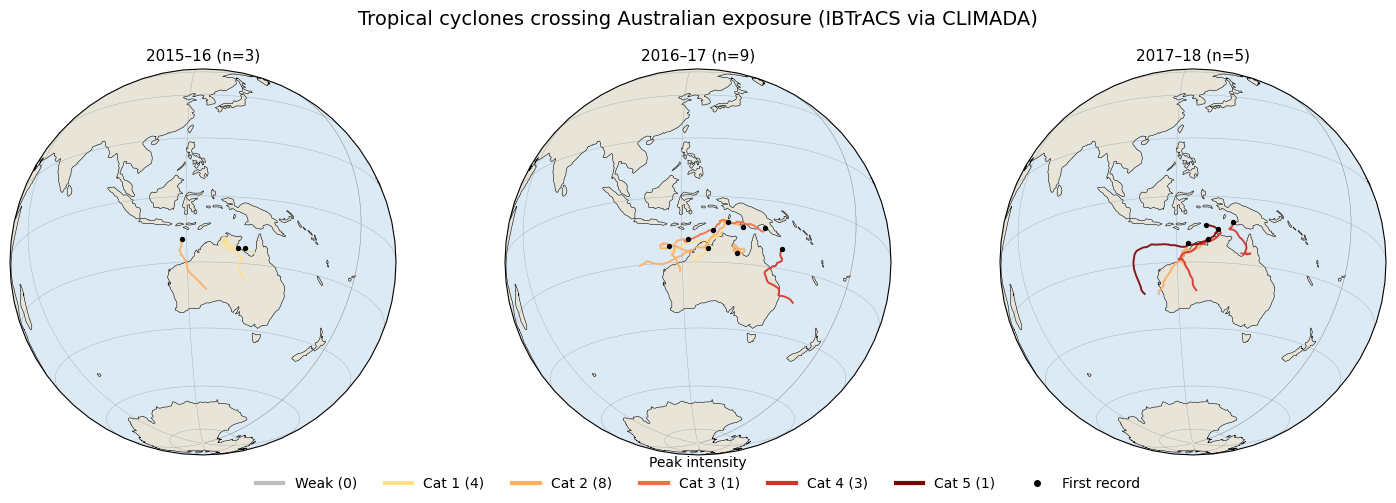

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

from climada.entity import LitPop, Exposures
from climada.hazard import TCTracks

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
# Exposure
my_country = 'aus'
m, n = 1, 1
my_fin_mode = 'pc'
ref_year = 2023
my_res_arcsec = 600

# Hazard
start_year = 1980        # track loading range
end_year = 2023

# Track selection
SELECTION = "buffer"     # "buffer" (degrees, original method) or "km" (distance in km)
buffer = 1.0             # degrees, used if SELECTION == "buffer" (effective reach ~2x this)
km = 100                 # used if SELECTION == "km"

# ------------------------------------------------------------------
# Exposure
# ------------------------------------------------------------------
exp1 = LitPop.from_countries(my_country, my_res_arcsec, (m, n), my_fin_mode,
                             reference_year=ref_year)
exp1.check()

# Remove Lord Howe Island and Macquarie Island
exp = Exposures(exp1.gdf[exp1.geometry.x <= 155])
exp.check()


# ------------------------------------------------------------------
# Track selection
# ------------------------------------------------------------------
def tracks_in_exp(tracks, exposure, buffer=1.0):
    """Select tracks within `buffer` degrees of the exposure (both sides buffered)."""
    if buffer <= 0.0:
        raise ValueError(f"buffer={buffer} is invalid, must be above zero.")
    exp_buffer = exposure.gdf.buffer(distance=buffer, resolution=0).unary_union
    lines = tracks.to_geodataframe(split_lines_antimeridian=False).buffer(distance=buffer)
    hit = lines.intersects(exp_buffer)
    return TCTracks([t for j, t in enumerate(tracks.data) if hit[j]])


def tracks_within_km(tracks, exposure, km=100, crs="EPSG:3577"):
    """Select tracks passing within `km` of any exposure point (EPSG:3577 = Australian Albers, metres)."""
    if km <= 0:
        raise ValueError("km must be positive")
    pts = exposure.gdf.geometry
    if pts.crs is None:
        pts = pts.set_crs("EPSG:4326")
    exp_buffer = pts.to_crs(crs).buffer(km * 1000, resolution=16).unary_union

    lines = tracks.to_geodataframe(split_lines_antimeridian=False)
    if lines.crs is None:
        lines = lines.set_crs("EPSG:4326")
    hit = lines.to_crs(crs).geometry.intersects(exp_buffer).values
    return TCTracks([t for t, h in zip(tracks.data, hit) if h])


tracks = TCTracks.from_ibtracs_netcdf(year_range=(start_year - 1, end_year))

if SELECTION == "km":
    my_tracks = tracks_within_km(tracks, exp, km=km)
    print(f"Selection: within {km} km of exposure")
else:
    my_tracks = tracks_in_exp(tracks, exp, buffer=buffer)
    print(f"Selection: {buffer} degree buffer on exposure and tracks")

print(f"Total number of historical tracks: {tracks.size}")
print(f"Tracks crossing Australian exposure: {my_tracks.size}")


# ------------------------------------------------------------------
# Per-track summary
# ------------------------------------------------------------------
def season_of(track):
    """Season label = year the season ends (Southern Hemisphere: Jul-Jun)."""
    t0 = pd.Timestamp(track.time.values[0])
    if float(track.lat.values[0]) < 0:
        return t0.year + 1 if t0.month >= 7 else t0.year
    return t0.year


summary = pd.DataFrame({
    "sid":    [t.sid for t in my_tracks.data],
    "name":   [t.name for t in my_tracks.data],
    "season": [season_of(t) for t in my_tracks.data],
    "peak":   [float(np.nanmax(t.max_sustained_wind.values)) if t.max_sustained_wind.size else 0.0
               for t in my_tracks.data],
})
summary["peak"] = summary["peak"].fillna(0)
track_by_sid = {t.sid: t for t in my_tracks.data}

# Australian category scale (kt)
BINS   = [0, 34, 48, 64, 86, 108, np.inf]
LABELS = ["Weak", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
COLORS = ["#bdbdbd", "#fee08b", "#fdae61", "#f46d43", "#d73027", "#7f0000"]
CAT_COLOR = dict(zip(LABELS, COLORS))
summary["cat"] = pd.cut(summary["peak"], bins=BINS, labels=LABELS, right=False).astype(str)


# ------------------------------------------------------------------
# Plot: one figure, one subplot per season
# ------------------------------------------------------------------
def plot_tcs_by_season(start, end=None, ncols=3, panel_size=5,
                       central_lon=125, central_lat=-20,
                       show_genesis=True, save_path=None):
    end = start if end is None else end
    seasons = list(range(start, end + 1))
    ncols = min(ncols, len(seasons))
    nrows = int(np.ceil(len(seasons) / ncols))

    proj = ccrs.Orthographic(central_longitude=central_lon, central_latitude=central_lat)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size * ncols, panel_size * nrows),
                             subplot_kw={"projection": proj}, squeeze=False)
    axes = axes.ravel()

    for ax, season in zip(axes, seasons):
        sub = summary[summary["season"] == season]
        label = f"{season-1}–{str(season)[-2:]}"
        print(f"{label}: {len(sub)} tropical cyclones")

        ax.set_global()
        ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
        ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)

        # weakest first so stronger storms sit on top
        for row in sub.sort_values("peak").itertuples():
            tr = track_by_sid[row.sid]
            lon = np.rad2deg(np.unwrap(np.deg2rad(tr.lon.values)))  # avoid dateline jumps
            ax.plot(lon, tr.lat.values, transform=ccrs.PlateCarree(),
                    color=CAT_COLOR[row.cat], linewidth=1.4, alpha=0.9)
            if show_genesis:
                ax.scatter(lon[0], tr.lat.values[0], transform=ccrs.PlateCarree(),
                           s=8, color="k", zorder=5)

        ax.set_title(f"{label} (n={len(sub)})", fontsize=11)

    # hide any unused panels
    for ax in axes[len(seasons):]:
        ax.set_visible(False)

    # one shared legend, with counts over all plotted seasons
    all_sub = summary[summary["season"].between(start, end)]
    counts = all_sub["cat"].value_counts()
    handles = [Line2D([0], [0], color=CAT_COLOR[l], lw=3,
                      label=f"{l} ({counts.get(l, 0)})") for l in LABELS]
    if show_genesis:
        handles.append(Line2D([0], [0], marker="o", color="k", lw=0,
                              markersize=4, label="First record"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               title="Peak intensity", frameon=False)

    fig.suptitle("Tropical cyclones crossing Australian exposure (IBTrACS via CLIMADA)",
                 fontsize=14)
    fig.tight_layout(rect=(0, 0.06, 1, 0.96))

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes


2011–12: 6 tropical cyclones
2012–13: 5 tropical cyclones
2013–14: 8 tropical cyclones
2014–15: 5 tropical cyclones
2015–16: 3 tropical cyclones
2016–17: 9 tropical cyclones
2017–18: 5 tropical cyclones
2018–19: 7 tropical cyclones
2019–20: 5 tropical cyclones


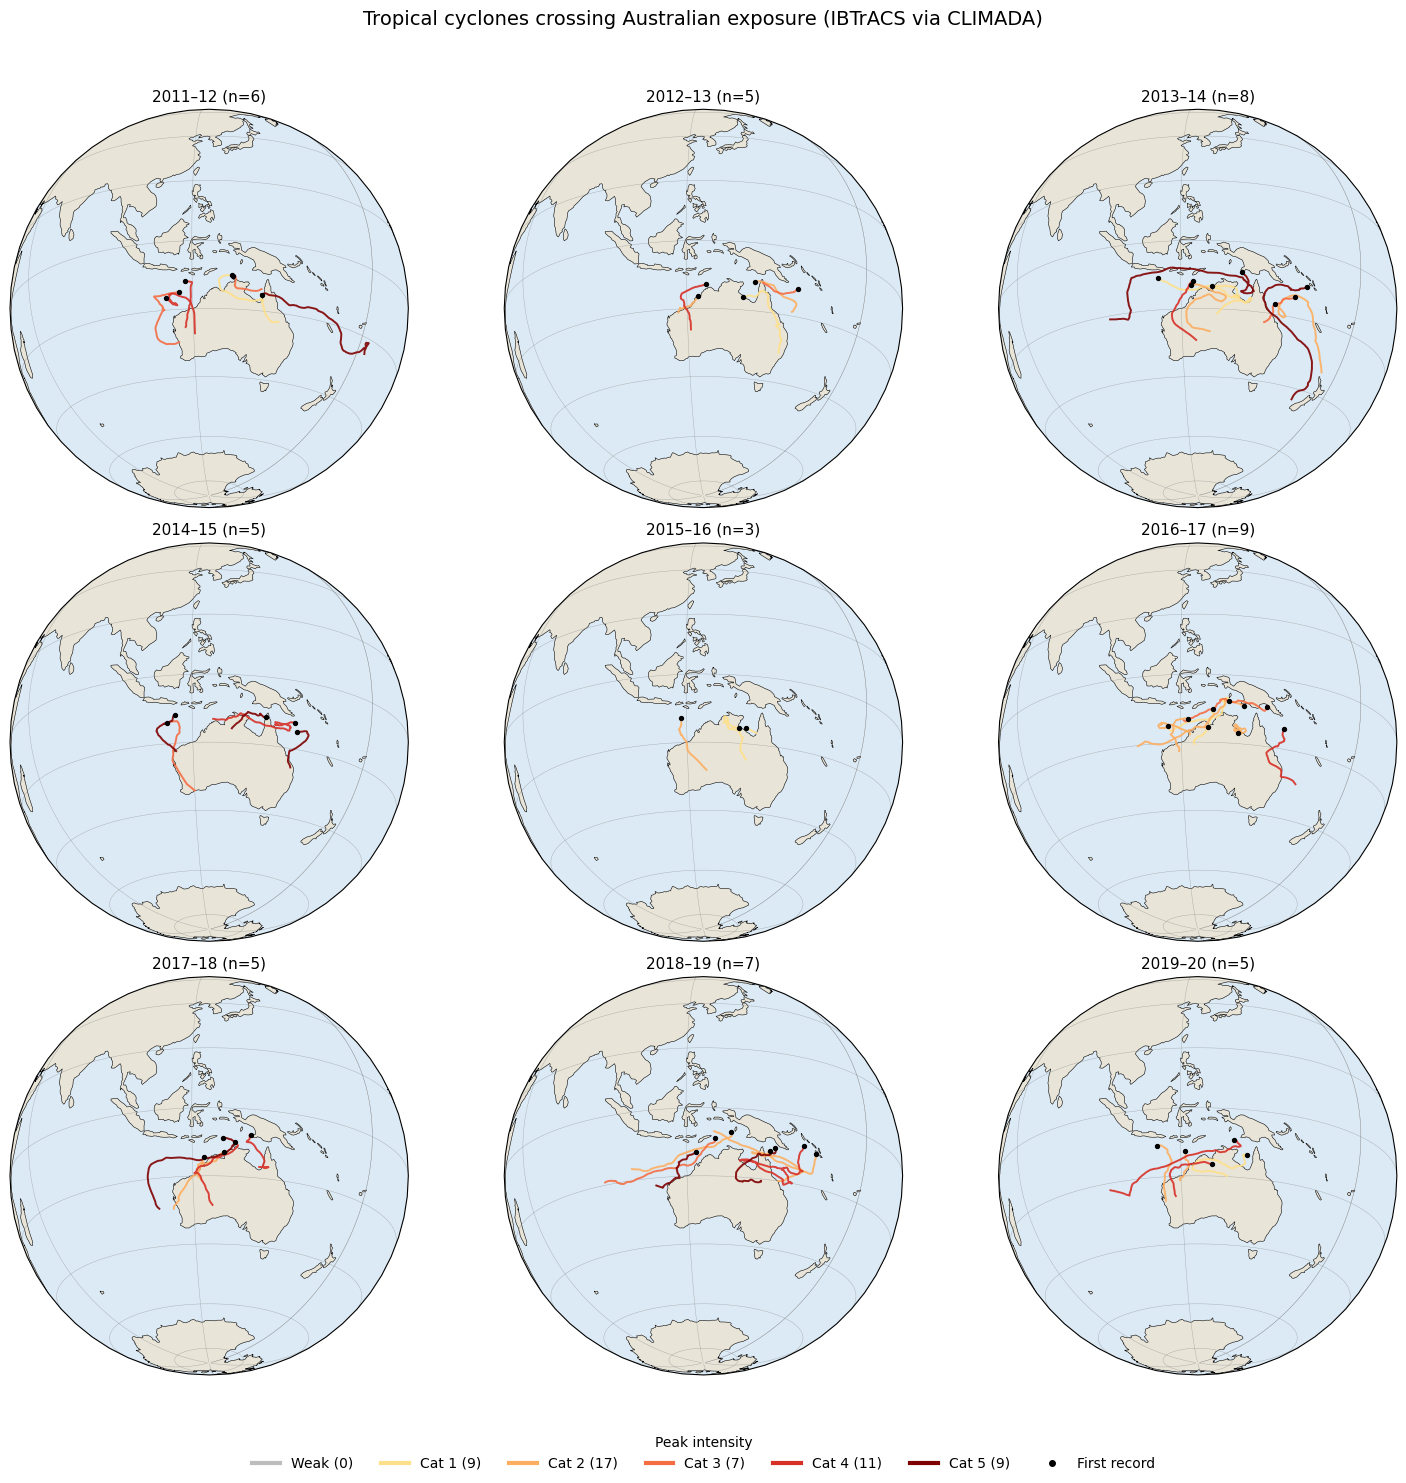

In [4]:
fig, axes = plot_tcs_by_season(2012, 2020, ncols=3)
plt.show()


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

from climada.hazard import TCTracks

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
IBTRACS_PATH = "../ibtracs.since1980.list.v04r01.csv"
AU_SUBBASINS = ("WA", "EA")

start_year = 1980        # hazard/track loading range
end_year = 2023

# ------------------------------------------------------------------
# Subbasin filter from the IBTrACS CSV
# ------------------------------------------------------------------
_ib = pd.read_csv(IBTRACS_PATH, usecols=["SID", "SEASON", "SUBBASIN"], low_memory=False)
_ib["SEASON"] = pd.to_numeric(_ib["SEASON"], errors="coerce")   # also drops the units row
_ib = _ib.dropna(subset=["SEASON"])

SID_TO_SEASON = _ib.drop_duplicates("SID").set_index("SID")["SEASON"].astype(int).to_dict()
AU_SIDS = set(_ib.loc[_ib["SUBBASIN"].isin(AU_SUBBASINS), "SID"])
print(f"{len(AU_SIDS)} storms have at least one point in {AU_SUBBASINS}")

# ------------------------------------------------------------------
# Load CLIMADA tracks and keep storms that pass through WA or EA
# ------------------------------------------------------------------
tracks = TCTracks.from_ibtracs_netcdf(year_range=(start_year - 1, end_year))
my_tracks = TCTracks([t for t in tracks.data if t.sid in AU_SIDS])

print(f"Total number of historical tracks: {tracks.size}")
print(f"Tracks passing through {AU_SUBBASINS}: {my_tracks.size}")


# ------------------------------------------------------------------
# Per-track summary
# ------------------------------------------------------------------
def season_of(track):
    """IBTrACS SEASON (year the season ends); falls back to a Jul-Jun rule."""
    s = SID_TO_SEASON.get(track.sid)
    if s is not None:
        return s
    t0 = pd.Timestamp(track.time.values[0])
    return t0.year + 1 if t0.month >= 7 else t0.year


summary = pd.DataFrame({
    "sid":    [t.sid for t in my_tracks.data],
    "name":   [t.name for t in my_tracks.data],
    "season": [season_of(t) for t in my_tracks.data],
    "peak":   [float(np.nanmax(t.max_sustained_wind.values)) if t.max_sustained_wind.size else 0.0
               for t in my_tracks.data],
})
summary["peak"] = summary["peak"].fillna(0)
track_by_sid = {t.sid: t for t in my_tracks.data}

# Australian category scale (kt)
BINS   = [0, 34, 48, 64, 86, 108, np.inf]
LABELS = ["Weak", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
COLORS = ["#bdbdbd", "#fee08b", "#fdae61", "#f46d43", "#d73027", "#7f0000"]
CAT_COLOR = dict(zip(LABELS, COLORS))
summary["cat"] = pd.cut(summary["peak"], bins=BINS, labels=LABELS, right=False).astype(str)


# ------------------------------------------------------------------
# Plot: one figure, one subplot per season
# ------------------------------------------------------------------
def plot_tcs_by_season(start, end=None, ncols=3, panel_size=5,
                       central_lon=125, central_lat=-20,
                       show_genesis=True, save_path=None):
    end = start if end is None else end
    seasons = list(range(start, end + 1))
    ncols = min(ncols, len(seasons))
    nrows = int(np.ceil(len(seasons) / ncols))

    proj = ccrs.Orthographic(central_longitude=central_lon, central_latitude=central_lat)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size * ncols, panel_size * nrows),
                             subplot_kw={"projection": proj}, squeeze=False)
    axes = axes.ravel()

    for ax, season in zip(axes, seasons):
        sub = summary[summary["season"] == season]
        label = f"{season-1}–{str(season)[-2:]}"
        print(f"{label}: {len(sub)} tropical cyclones")

        ax.set_global()
        ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
        ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)

        # weakest first so stronger storms sit on top
        for row in sub.sort_values("peak").itertuples():
            tr = track_by_sid[row.sid]
            lon = np.rad2deg(np.unwrap(np.deg2rad(tr.lon.values)))  # avoid dateline jumps
            ax.plot(lon, tr.lat.values, transform=ccrs.PlateCarree(),
                    color=CAT_COLOR[row.cat], linewidth=1.4, alpha=0.9)
            if show_genesis:
                ax.scatter(lon[0], tr.lat.values[0], transform=ccrs.PlateCarree(),
                           s=8, color="k", zorder=5)

        ax.set_title(f"{label} (n={len(sub)})", fontsize=11)

    # hide any unused panels
    for ax in axes[len(seasons):]:
        ax.set_visible(False)

    # one shared legend, with counts over all plotted seasons
    all_sub = summary[summary["season"].between(start, end)]
    counts = all_sub["cat"].value_counts()
    handles = [Line2D([0], [0], color=CAT_COLOR[l], lw=3,
                      label=f"{l} ({counts.get(l, 0)})") for l in LABELS]
    if show_genesis:
        handles.append(Line2D([0], [0], marker="o", color="k", lw=0,
                              markersize=4, label="First record"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               title="Peak intensity", frameon=False)

    fig.suptitle("Tropical cyclones passing through WA/EA subbasins (IBTrACS via CLIMADA)",
                 fontsize=14)
    fig.tight_layout(rect=(0, 0.06, 1, 0.96))

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes


649 storms have at least one point in ('WA', 'EA')
2026-10-09 01:04:27,960 - climada.hazard.tc_tracks - WARNING - 571 storm events are discarded because no valid wind/pressure values have been found: 1979033S18151, 1979090S12168, 1979118S06094, 1979126N07090, 1979152N11265, ...
2026-10-09 01:04:27,987 - climada.hazard.tc_tracks - WARNING - 15 storm events are discarded because only one valid timestep has been found: 1979045S18053, 1980002S15081, 1980005S11059, 1980009S14066, 1980010S20043, ...
Total number of historical tracks: 4215
Tracks passing through ('WA', 'EA'): 591


2011–12: 13 tropical cyclones
2012–13: 11 tropical cyclones
2013–14: 13 tropical cyclones
2014–15: 13 tropical cyclones
2015–16: 6 tropical cyclones
2016–17: 12 tropical cyclones
2017–18: 12 tropical cyclones
2018–19: 16 tropical cyclones
2019–20: 13 tropical cyclones


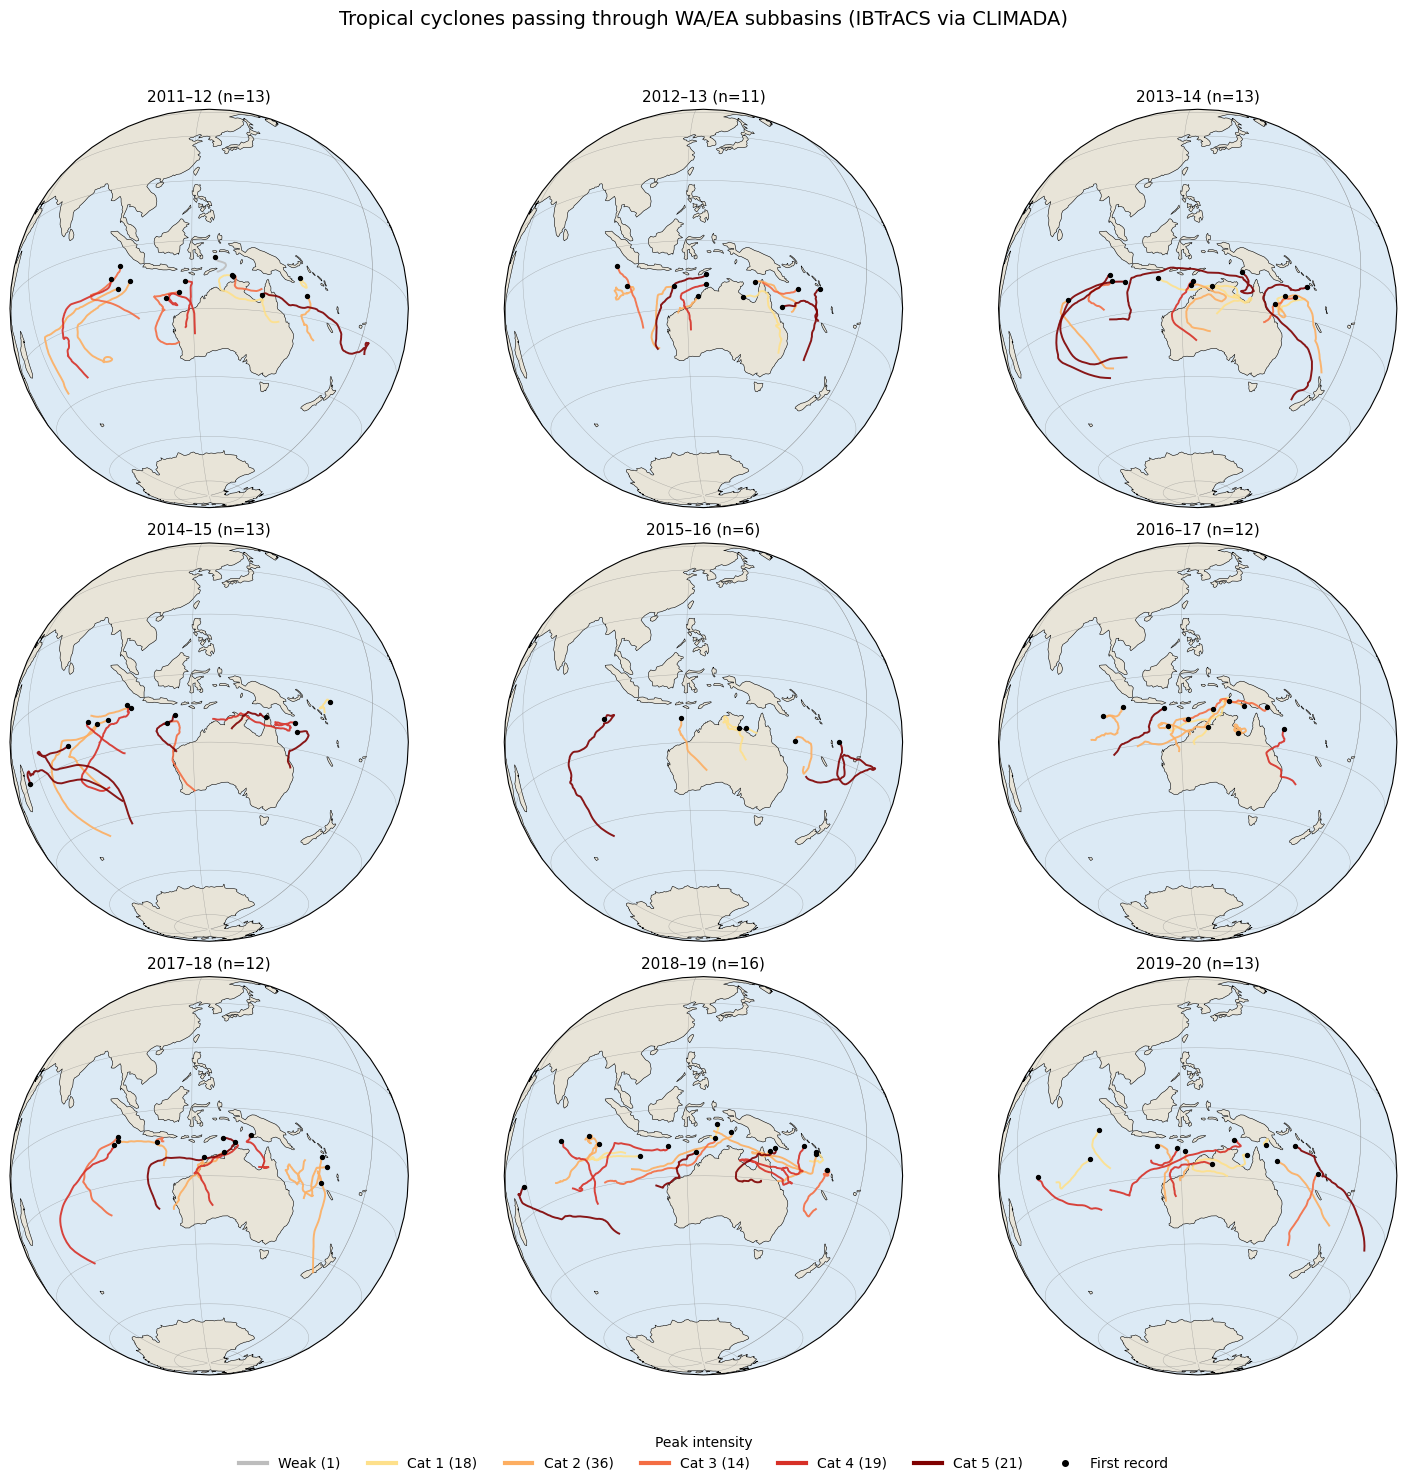

In [6]:
plot_start = 2012
plot_end = 2020
fig, axes = plot_tcs_by_season(plot_start, plot_end, ncols=3)
plt.show()


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

from climada.hazard import TCTracks

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
IBTRACS_PATH = "../ibtracs.since1980.list.v04r01.csv"
BASINS = ("SP", "SI")

start_year = 1980        # hazard/track loading range
end_year = 2023

# ------------------------------------------------------------------
# Subbasin filter from the IBTrACS CSV
# ------------------------------------------------------------------
_ib = pd.read_csv(IBTRACS_PATH, usecols=["SID", "SEASON", "BASIN"], low_memory=False)
_ib["SEASON"] = pd.to_numeric(_ib["SEASON"], errors="coerce")   # also drops the units row
_ib = _ib.dropna(subset=["SEASON"])

SID_TO_SEASON = _ib.drop_duplicates("SID").set_index("SID")["SEASON"].astype(int).to_dict()
AU_SIDS = set(_ib.loc[_ib["BASIN"].isin(BASINS), "SID"])
print(f"{len(AU_SIDS)} storms have at least one point in {BASINS}")

# ------------------------------------------------------------------
# Load CLIMADA tracks and keep storms that pass through WA or EA
# ------------------------------------------------------------------
tracks = TCTracks.from_ibtracs_netcdf(year_range=(start_year - 1, end_year))
my_tracks = TCTracks([t for t in tracks.data if t.sid in AU_SIDS])

print(f"Total number of historical tracks: {tracks.size}")
print(f"Tracks passing through {BASINS}: {my_tracks.size}")


# ------------------------------------------------------------------
# Per-track summary
# ------------------------------------------------------------------
def season_of(track):
    """IBTrACS SEASON (year the season ends); falls back to a Jul-Jun rule."""
    s = SID_TO_SEASON.get(track.sid)
    if s is not None:
        return s
    t0 = pd.Timestamp(track.time.values[0])
    return t0.year + 1 if t0.month >= 7 else t0.year


summary = pd.DataFrame({
    "sid":    [t.sid for t in my_tracks.data],
    "name":   [t.name for t in my_tracks.data],
    "season": [season_of(t) for t in my_tracks.data],
    "peak":   [float(np.nanmax(t.max_sustained_wind.values)) if t.max_sustained_wind.size else 0.0
               for t in my_tracks.data],
})
summary["peak"] = summary["peak"].fillna(0)
track_by_sid = {t.sid: t for t in my_tracks.data}

# Australian category scale (kt)
BINS   = [0, 34, 48, 64, 86, 108, np.inf]
LABELS = ["Weak", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
COLORS = ["#bdbdbd", "#fee08b", "#fdae61", "#f46d43", "#d73027", "#7f0000"]
CAT_COLOR = dict(zip(LABELS, COLORS))
summary["cat"] = pd.cut(summary["peak"], bins=BINS, labels=LABELS, right=False).astype(str)


# ------------------------------------------------------------------
# Plot: one figure, one subplot per season
# ------------------------------------------------------------------
def plot_tcs_by_season(start, end=None, ncols=3, panel_size=5,
                       central_lon=125, central_lat=-20,
                       show_genesis=True, save_path=None):
    end = start if end is None else end
    seasons = list(range(start, end + 1))
    ncols = min(ncols, len(seasons))
    nrows = int(np.ceil(len(seasons) / ncols))

    proj = ccrs.Orthographic(central_longitude=central_lon, central_latitude=central_lat)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size * ncols, panel_size * nrows),
                             subplot_kw={"projection": proj}, squeeze=False)
    axes = axes.ravel()

    for ax, season in zip(axes, seasons):
        sub = summary[summary["season"] == season]
        label = f"{season-1}–{str(season)[-2:]}"
        print(f"{label}: {len(sub)} tropical cyclones")

        ax.set_global()
        ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
        ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)

        # weakest first so stronger storms sit on top
        for row in sub.sort_values("peak").itertuples():
            tr = track_by_sid[row.sid]
            lon = np.rad2deg(np.unwrap(np.deg2rad(tr.lon.values)))  # avoid dateline jumps
            ax.plot(lon, tr.lat.values, transform=ccrs.PlateCarree(),
                    color=CAT_COLOR[row.cat], linewidth=1.4, alpha=0.9)
            if show_genesis:
                ax.scatter(lon[0], tr.lat.values[0], transform=ccrs.PlateCarree(),
                           s=8, color="k", zorder=5)

        ax.set_title(f"{label} (n={len(sub)})", fontsize=11)

    # hide any unused panels
    for ax in axes[len(seasons):]:
        ax.set_visible(False)

    # one shared legend, with counts over all plotted seasons
    all_sub = summary[summary["season"].between(start, end)]
    counts = all_sub["cat"].value_counts()
    handles = [Line2D([0], [0], color=CAT_COLOR[l], lw=3,
                      label=f"{l} ({counts.get(l, 0)})") for l in LABELS]
    if show_genesis:
        handles.append(Line2D([0], [0], marker="o", color="k", lw=0,
                              markersize=4, label="First record"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               title="Peak intensity", frameon=False)

    fig.suptitle("Tropical cyclones passing through SI/SP subbasins (IBTrACS via CLIMADA)",
                 fontsize=14)
    fig.tight_layout(rect=(0, 0.06, 1, 0.96))

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes


1355 storms have at least one point in ('SP', 'SI')
2026-10-09 01:43:57,646 - climada.hazard.tc_tracks - WARNING - 571 storm events are discarded because no valid wind/pressure values have been found: 1979033S18151, 1979090S12168, 1979118S06094, 1979126N07090, 1979152N11265, ...
2026-10-09 01:43:57,696 - climada.hazard.tc_tracks - WARNING - 15 storm events are discarded because only one valid timestep has been found: 1979045S18053, 1980002S15081, 1980005S11059, 1980009S14066, 1980010S20043, ...
Total number of historical tracks: 4215
Tracks passing through ('SP', 'SI'): 1173


2011–12: 24 tropical cyclones
2012–13: 24 tropical cyclones
2013–14: 26 tropical cyclones
2014–15: 25 tropical cyclones
2015–16: 21 tropical cyclones
2016–17: 24 tropical cyclones
2017–18: 22 tropical cyclones
2018–19: 29 tropical cyclones
2019–20: 28 tropical cyclones


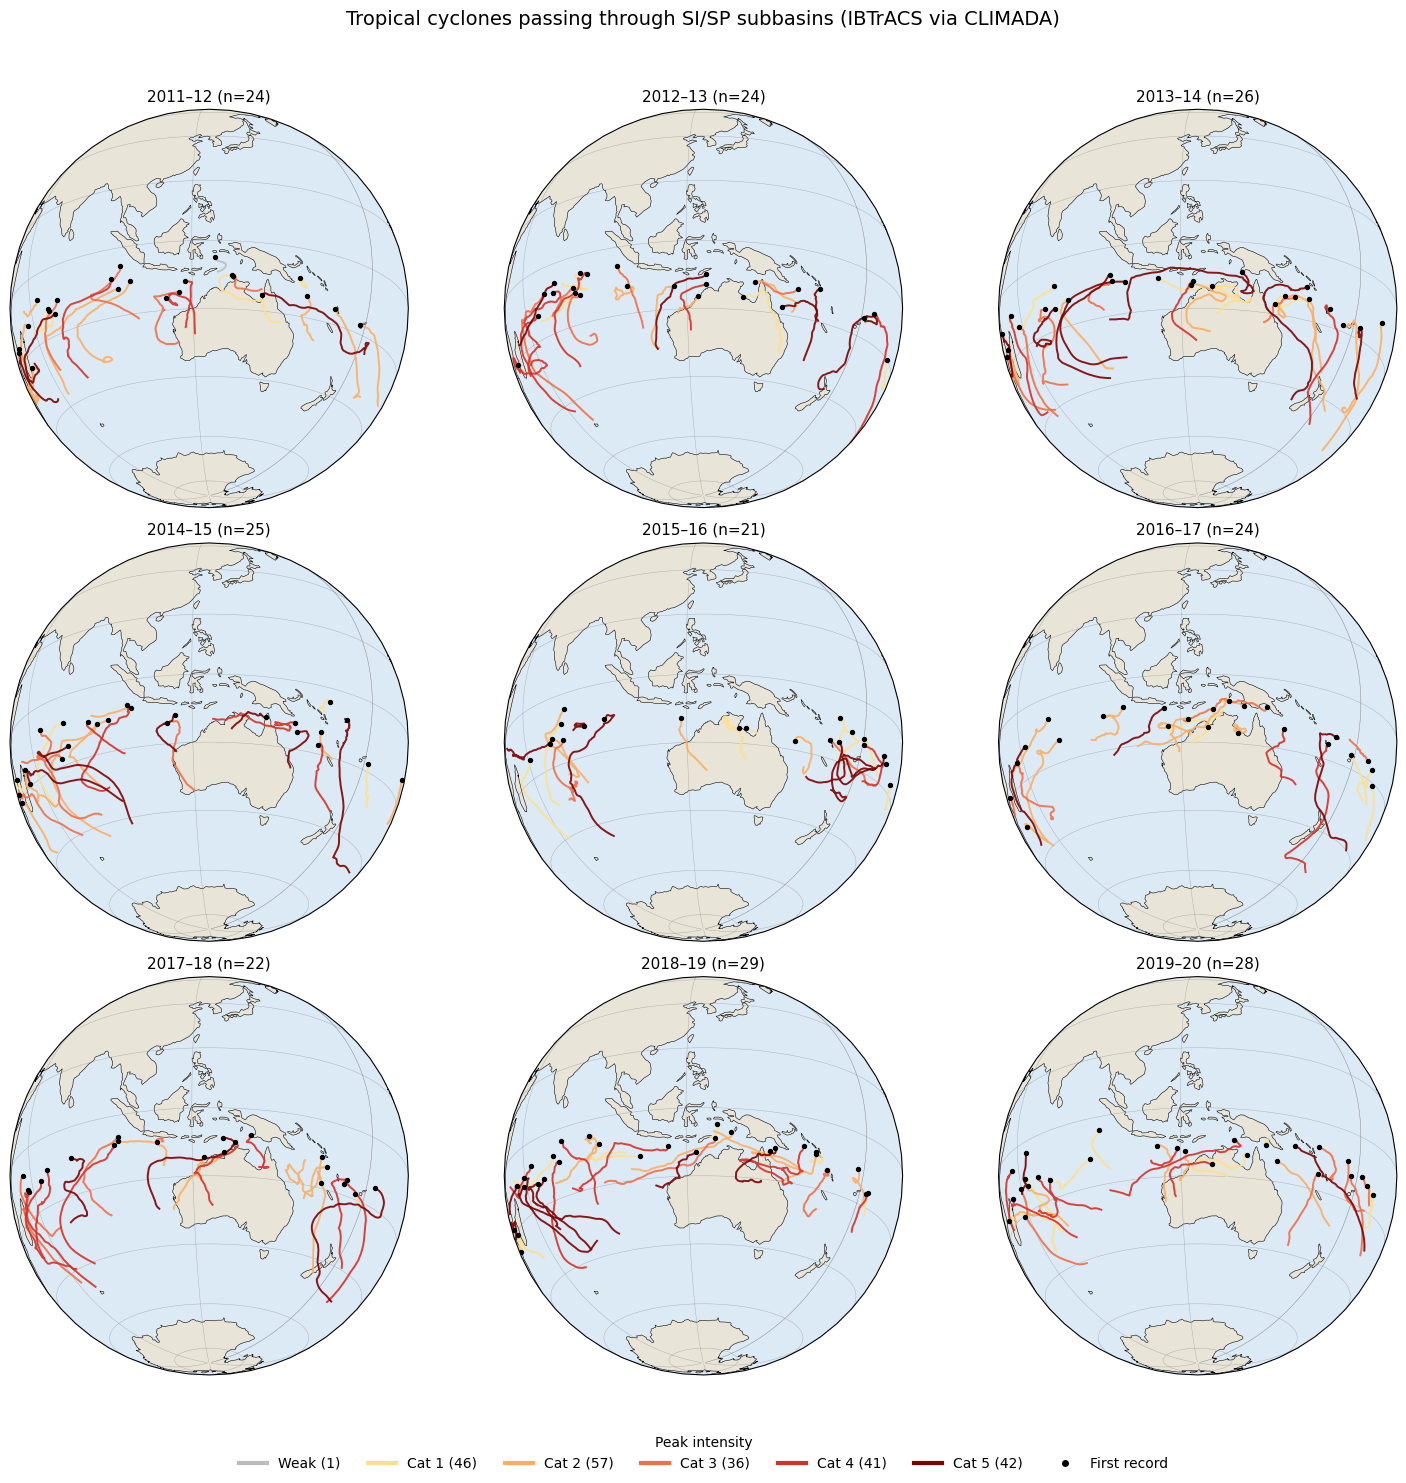

In [17]:
plot_start = 2012
plot_end = 2020
fig, axes = plot_tcs_by_season(plot_start, plot_end, ncols=3)
plt.show()


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from matplotlib.lines import Line2D

from climada.hazard import TCTracks
from helper import read_simulations_AI

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
IBTRACS_PATH = "../ibtracs.since1980.list.v04r01.csv"
AI_DIR = Path("../TC_datasets/MiniTC-QM")
AU_SUBBASINS = ("WA", "EA")
MAX_DIST_DEG = 8.0                   # matching tolerance for read_simulations_AI

start_year = 1980                    # track loading range (calendar years of SID)
end_year = 2020
plot_start, plot_end = 2000, 2020
# ------------------------------------------------------------------
# Subbasin filter from the IBTrACS CSV
# ------------------------------------------------------------------
_ib = pd.read_csv(IBTRACS_PATH, usecols=["SID", "SEASON", "SUBBASIN"], low_memory=False)
_ib["SEASON"] = pd.to_numeric(_ib["SEASON"], errors="coerce")   # also drops the units row
_ib = _ib.dropna(subset=["SEASON"])

SID_TO_SEASON = _ib.drop_duplicates("SID").set_index("SID")["SEASON"].astype(int).to_dict()
AU_SIDS = set(_ib.loc[_ib["SUBBASIN"].isin(AU_SUBBASINS), "SID"])
print(f"{len(AU_SIDS)} storms have at least one point in {AU_SUBBASINS}")

# ------------------------------------------------------------------
# Load CLIMADA tracks, keep storms passing through WA or EA
# ------------------------------------------------------------------
tracks = TCTracks.from_ibtracs_netcdf(year_range=(start_year - 1, end_year))
my_tracks = TCTracks([t for t in tracks.data if t.sid in AU_SIDS])
print(f"Total historical tracks: {tracks.size}; passing through {AU_SUBBASINS}: {my_tracks.size}")


def season_of(track):
    s = SID_TO_SEASON.get(track.sid)
    if s is not None:
        return s
    t0 = pd.Timestamp(track.time.values[0])
    return t0.year + 1 if t0.month >= 7 else t0.year


# ------------------------------------------------------------------
# Per-track summary
# ------------------------------------------------------------------
summary = pd.DataFrame({
    "sid":    [t.sid for t in my_tracks.data],
    "name":   [t.name for t in my_tracks.data],
    "season": [season_of(t) for t in my_tracks.data],
    "peak":   [float(np.nanmax(t.max_sustained_wind.values)) if t.max_sustained_wind.size else 0.0
               for t in my_tracks.data],
})
summary["peak"] = summary["peak"].fillna(0)
track_by_sid = {t.sid: t for t in my_tracks.data}

BINS   = [0, 34, 48, 64, 86, 108, np.inf]
LABELS = ["Weak", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
COLORS = ["#bdbdbd", "#fee08b", "#fdae61", "#f46d43", "#d73027", "#7f0000"]
CAT_COLOR = dict(zip(LABELS, COLORS))
summary["cat"] = pd.cut(summary["peak"], bins=BINS, labels=LABELS, right=False).astype(str)


# ------------------------------------------------------------------
# Retrieve WeatherNext AI ensemble tracks for the plotted seasons
# ------------------------------------------------------------------
def load_ai_tracks(sub, ai_dir=AI_DIR, max_dist_deg=MAX_DIST_DEG):
    """Return {sid: [ai_track, ...]} for storms in `sub` that have an ensemble file."""
    ai = {}
    n_missing = 0
    for sid in sub["sid"]:
        f = Path(ai_dir) / f"{sid}.csv"
        if not f.is_file():
            n_missing += 1
            continue
        tr = track_by_sid[sid]
        event = pd.Series({
            "SID": sid,
            "LAT": float(tr.lat.values[0]),
            "LON": float(tr.lon.values[0]),
            "ISO_TIME": pd.Timestamp(tr.time.values[0]),
        })
        try:
            matched = read_simulations_AI(path=f, IBTrACS_event=event, max_dist_deg=max_dist_deg)
        except Exception as e:
            print(f"[error] {sid}: {e}")
            continue
        if matched:
            ai[sid] = matched
    print(f"AI ensembles: {len(ai)} storms matched, {n_missing} with no file "
          f"(of {len(sub)} storms plotted)")
    return ai


plot_sub = summary[summary["season"].between(plot_start, plot_end)]
ai_tracks = load_ai_tracks(plot_sub)


# ------------------------------------------------------------------
# Plot: one figure, one subplot per season
# ------------------------------------------------------------------
def unwrap_lon(lon):
    return np.rad2deg(np.unwrap(np.deg2rad(np.asarray(lon, dtype=float))))


def plot_tcs_by_season(start, end=None, ncols=3, panel_size=6,
                       central_lon=125, central_lat=-20,
                       show_genesis=True, label_ai=True, save_path=None):
    end = start if end is None else end
    seasons = list(range(start, end + 1))
    ncols = min(ncols, len(seasons))
    nrows = int(np.ceil(len(seasons) / ncols))

    proj = ccrs.Orthographic(central_longitude=central_lon, central_latitude=central_lat)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size * ncols, panel_size * nrows),
                             subplot_kw={"projection": proj}, squeeze=False)
    axes = axes.ravel()

    for ax, season in zip(axes, seasons):
        sub = summary[summary["season"] == season]
        n_ai = sum(s in ai_tracks for s in sub["sid"])
        label = f"{season-1}–{str(season)[-2:]}"
        print(f"{label}: {len(sub)} tropical cyclones, {n_ai} with AI ensembles")

        ax.set_global()
        ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
        ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)

        # AI ensemble members first (thin, underneath)
        for row in sub.itertuples():
            for ds in ai_tracks.get(row.sid, []):
                ax.plot(unwrap_lon(ds.lon.values), ds.lat.values,
                        transform=ccrs.PlateCarree(), color=CAT_COLOR[row.cat],
                        lw=0.7, alpha=0.4, zorder=2)

        # IBTrACS observed tracks, weakest first so stronger sit on top
        for row in sub.sort_values("peak").itertuples():
            tr = track_by_sid[row.sid]
            lon = unwrap_lon(tr.lon.values)
            ax.plot(lon, tr.lat.values, transform=ccrs.PlateCarree(),
                    color=CAT_COLOR[row.cat], lw=1.8, zorder=4,
                    path_effects=[pe.Stroke(linewidth=3.4, foreground="white"), pe.Normal()])
            if show_genesis:
                ax.scatter(lon[0], tr.lat.values[0], transform=ccrs.PlateCarree(),
                           s=8, color="k", zorder=5)
            if label_ai and row.sid in ai_tracks:
                name = row.name if row.name not in ("NOT_NAMED", "UNNAMED") else row.sid
                ax.text(lon[0], tr.lat.values[0], f" {name} ({len(ai_tracks[row.sid])})",
                        transform=ccrs.PlateCarree(), fontsize=7, zorder=6,
                        path_effects=[pe.withStroke(linewidth=2, foreground="white")])

        ax.set_title(f"{label} (n={len(sub)}, {n_ai} with AI)", fontsize=11)

    for ax in axes[len(seasons):]:
        ax.set_visible(False)

    # shared legend
    all_sub = summary[summary["season"].between(start, end)]
    counts = all_sub["cat"].value_counts()
    handles = [Line2D([0], [0], color=CAT_COLOR[l], lw=3,
                      label=f"{l} ({counts.get(l, 0)})") for l in LABELS]
    handles += [
        Line2D([0], [0], color="gray", lw=2.5, label="IBTrACS observed (thick)"),
        Line2D([0], [0], color="gray", lw=0.8, alpha=0.6,
               label=f"WeatherNext ensemble (thin, {sum(len(v) for v in ai_tracks.values())} members)"),
    ]
    if show_genesis:
        handles.append(Line2D([0], [0], marker="o", color="k", lw=0,
                              markersize=4, label="First record"))
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
               title="Peak intensity (colour); labels show storm name (ensemble members)")

    fig.suptitle("Tropical cyclones through WA/EA: IBTrACS vs WeatherNext ensemble", fontsize=14)
    fig.tight_layout(rect=(0, 0.1, 1, 0.96))

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes


649 storms have at least one point in ('WA', 'EA')
2026-10-09 02:07:25,040 - climada.hazard.tc_tracks - WARNING - 571 storm events are discarded because no valid wind/pressure values have been found: 1979033S18151, 1979090S12168, 1979118S06094, 1979126N07090, 1979152N11265, ...
2026-10-09 02:07:25,070 - climada.hazard.tc_tracks - WARNING - 15 storm events are discarded because only one valid timestep has been found: 1979045S18053, 1980002S15081, 1980005S11059, 1980009S14066, 1980010S20043, ...
Total historical tracks: 3906; passing through ('WA', 'EA'): 541
Successfully loaded 30 matching tracks out of 30 samples.
Sample 0: Track 2000056S has only 2 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 1: Track 2000056S has only 3 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 3: Track 2000056S has only 2 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 5: Track 2000056S has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 13: Track 2

2009–10: 10 tropical cyclones, 7 with AI ensembles
2010–11: 15 tropical cyclones, 14 with AI ensembles
2011–12: 13 tropical cyclones, 10 with AI ensembles
2012–13: 11 tropical cyclones, 7 with AI ensembles
2013–14: 13 tropical cyclones, 9 with AI ensembles
2014–15: 13 tropical cyclones, 11 with AI ensembles
2015–16: 6 tropical cyclones, 4 with AI ensembles
2016–17: 12 tropical cyclones, 11 with AI ensembles


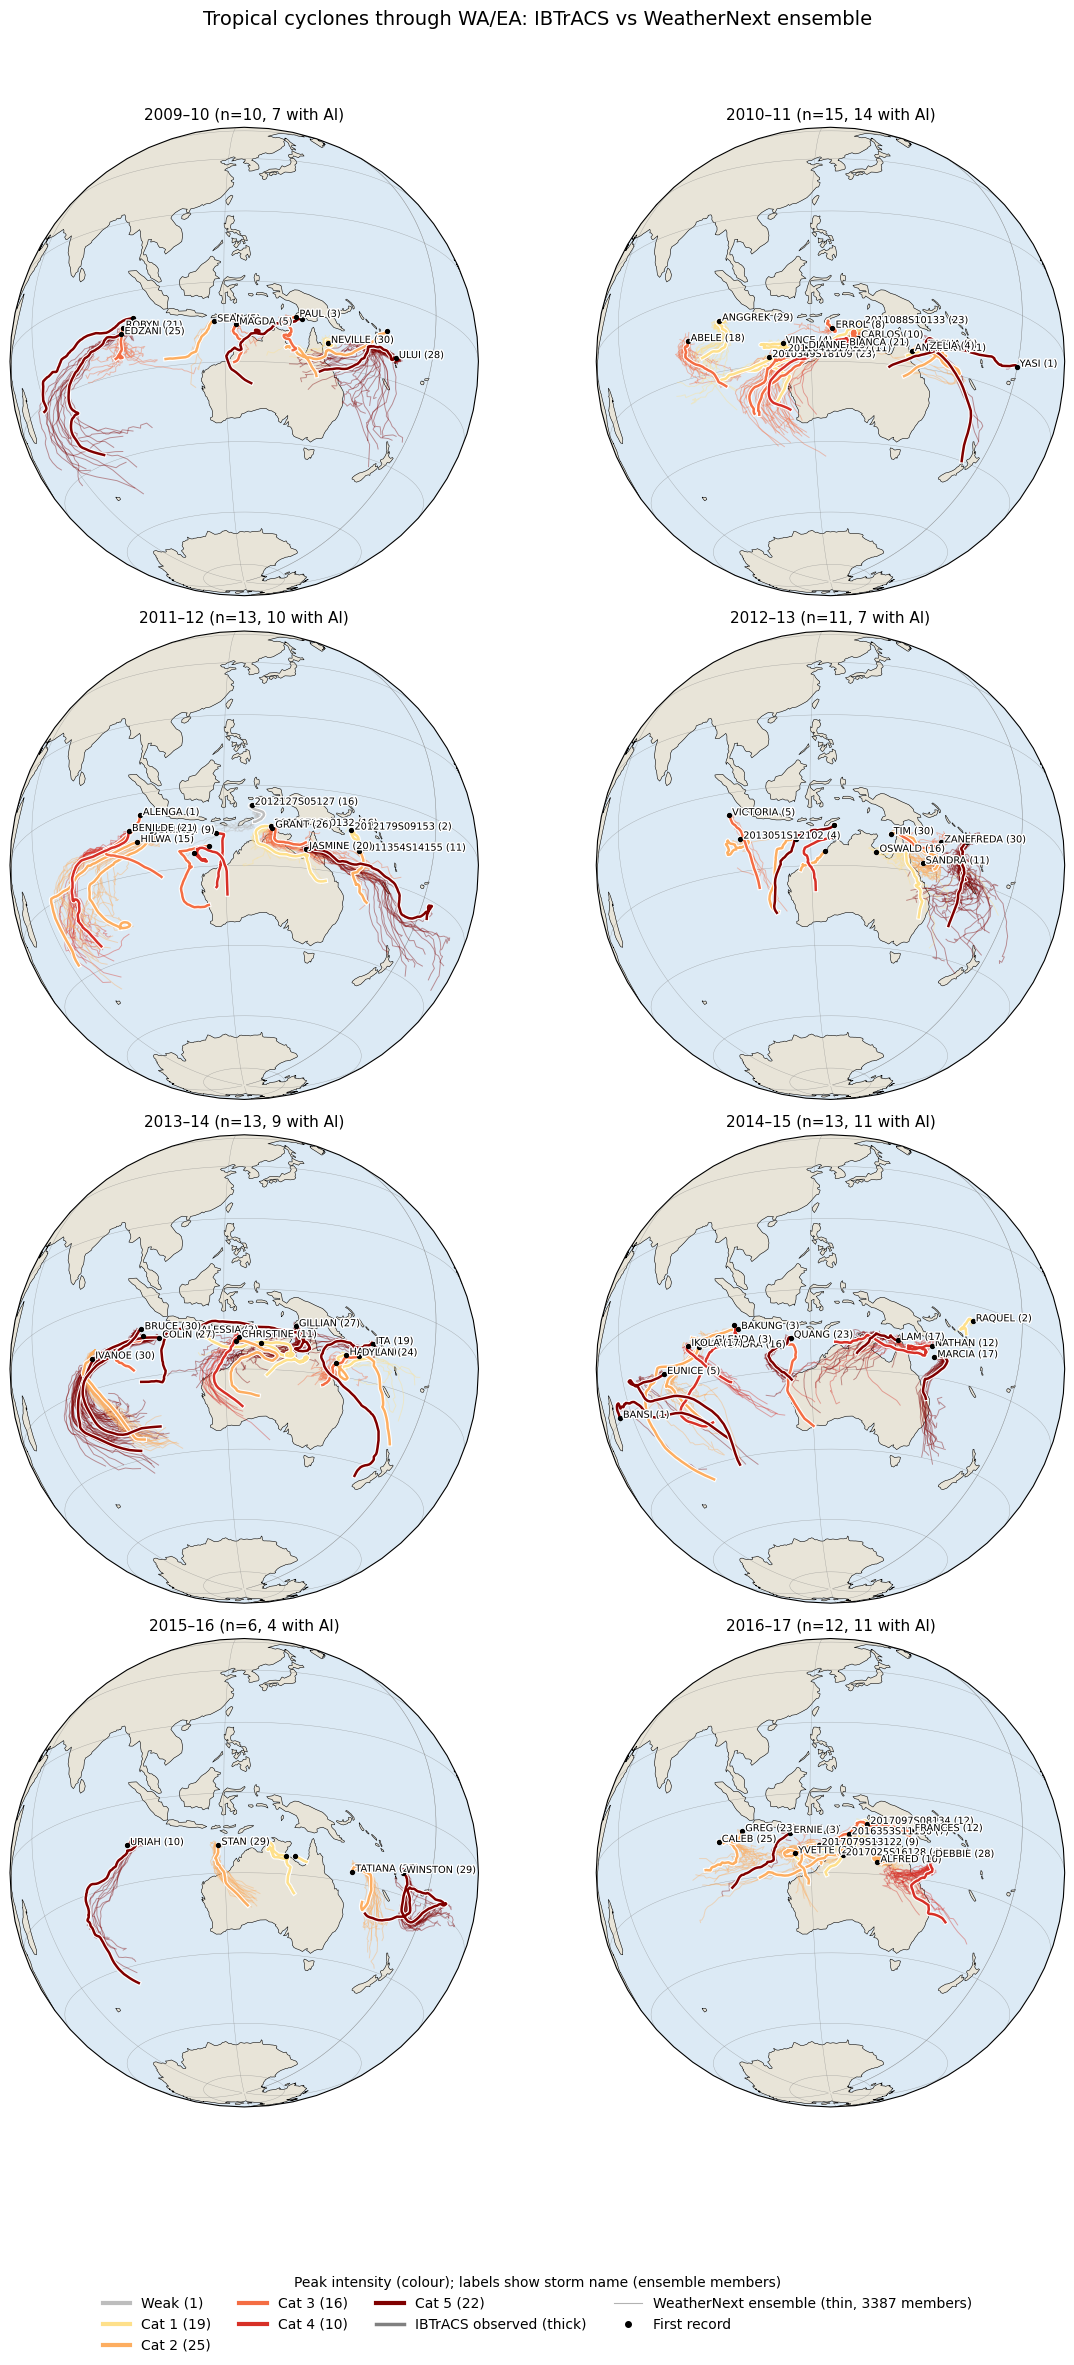

In [22]:
plot_start, plot_end = 2010, 2017 
fig, axes = plot_tcs_by_season(plot_start, plot_end, ncols=2)
plt.show()


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from matplotlib.lines import Line2D

from climada.hazard import TCTracks
from helper import read_simulations_AI

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
IBTRACS_PATH = "../ibtracs.since1980.list.v04r01.csv"
AI_DIR = Path("../TC_datasets/MiniTC-QM")
AU_SUBBASINS = ("WA", "EA")
BASIN = "SH"
MAX_DIST_DEG = 8.0                   # matching tolerance for read_simulations_AI

start_year = 1980                    # track loading range (calendar years of SID)
end_year = 2020

# ------------------------------------------------------------------
# Subbasin filter from the IBTrACS CSV
# ------------------------------------------------------------------
_ib = pd.read_csv(IBTRACS_PATH, usecols=["SID", "SEASON", "SUBBASIN"], low_memory=False)
_ib["SEASON"] = pd.to_numeric(_ib["SEASON"], errors="coerce")   # also drops the units row
_ib = _ib.dropna(subset=["SEASON"])

SID_TO_SEASON = _ib.drop_duplicates("SID").set_index("SID")["SEASON"].astype(int).to_dict()
AU_SIDS = set(_ib.loc[_ib["BASIN"].isin(BASIN), "SID"])
print(f"{len(AU_SIDS)} storms have at least one point in {BASIN}")

# ------------------------------------------------------------------
# Load CLIMADA tracks, keep storms passing through WA or EA
# ------------------------------------------------------------------
tracks = TCTracks.from_ibtracs_netcdf(year_range=(start_year - 1, end_year))
my_tracks = TCTracks([t for t in tracks.data if t.sid in AU_SIDS])
print(f"Total historical tracks: {tracks.size}; passing through {BASIN}: {my_tracks.size}")


def season_of(track):
    s = SID_TO_SEASON.get(track.sid)
    if s is not None:
        return s
    t0 = pd.Timestamp(track.time.values[0])
    return t0.year + 1 if t0.month >= 7 else t0.year


# ------------------------------------------------------------------
# Per-track summary
# ------------------------------------------------------------------
summary = pd.DataFrame({
    "sid":    [t.sid for t in my_tracks.data],
    "name":   [t.name for t in my_tracks.data],
    "season": [season_of(t) for t in my_tracks.data],
    "peak":   [float(np.nanmax(t.max_sustained_wind.values)) if t.max_sustained_wind.size else 0.0
               for t in my_tracks.data],
})
summary["peak"] = summary["peak"].fillna(0)
track_by_sid = {t.sid: t for t in my_tracks.data}

BINS   = [0, 34, 48, 64, 86, 108, np.inf]
LABELS = ["Weak", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
COLORS = ["#bdbdbd", "#fee08b", "#fdae61", "#f46d43", "#d73027", "#7f0000"]
CAT_COLOR = dict(zip(LABELS, COLORS))
summary["cat"] = pd.cut(summary["peak"], bins=BINS, labels=LABELS, right=False).astype(str)


# ------------------------------------------------------------------
# Retrieve WeatherNext AI ensemble tracks for the plotted seasons
# ------------------------------------------------------------------
def load_ai_tracks(sub, ai_dir=AI_DIR, max_dist_deg=MAX_DIST_DEG):
    """Return {sid: [ai_track, ...]} for storms in `sub` that have an ensemble file."""
    ai = {}
    n_missing = 0
    for sid in sub["sid"]:
        f = Path(ai_dir) / f"{sid}.csv"
        if not f.is_file():
            n_missing += 1
            continue
        tr = track_by_sid[sid]
        event = pd.Series({
            "SID": sid,
            "LAT": float(tr.lat.values[0]),
            "LON": float(tr.lon.values[0]),
            "ISO_TIME": pd.Timestamp(tr.time.values[0]),
        })
        try:
            matched = read_simulations_AI(path=f, IBTrACS_event=event, max_dist_deg=max_dist_deg)
        except Exception as e:
            print(f"[error] {sid}: {e}")
            continue
        if matched:
            ai[sid] = matched
    print(f"AI ensembles: {len(ai)} storms matched, {n_missing} with no file "
          f"(of {len(sub)} storms plotted)")
    return ai


plot_sub = summary[summary["season"].between(plot_start, plot_end)]
ai_tracks = load_ai_tracks(plot_sub)


# ------------------------------------------------------------------
# Plot: one figure, one subplot per season
# ------------------------------------------------------------------
def unwrap_lon(lon):
    return np.rad2deg(np.unwrap(np.deg2rad(np.asarray(lon, dtype=float))))


def plot_tcs_by_season(start, end=None, ncols=3, panel_size=6,
                       central_lon=125, central_lat=-20,
                       show_genesis=True, label_ai=True, save_path=None):
    end = start if end is None else end
    seasons = list(range(start, end + 1))
    ncols = min(ncols, len(seasons))
    nrows = int(np.ceil(len(seasons) / ncols))

    proj = ccrs.Orthographic(central_longitude=central_lon, central_latitude=central_lat)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size * ncols, panel_size * nrows),
                             subplot_kw={"projection": proj}, squeeze=False)
    axes = axes.ravel()

    for ax, season in zip(axes, seasons):
        sub = summary[summary["season"] == season]
        n_ai = sum(s in ai_tracks for s in sub["sid"])
        label = f"{season-1}–{str(season)[-2:]}"
        print(f"{label}: {len(sub)} tropical cyclones, {n_ai} with AI ensembles")

        ax.set_global()
        ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
        ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)

        # AI ensemble members first (thin, underneath)
        for row in sub.itertuples():
            for ds in ai_tracks.get(row.sid, []):
                ax.plot(unwrap_lon(ds.lon.values), ds.lat.values,
                        transform=ccrs.PlateCarree(), color=CAT_COLOR[row.cat],
                        lw=0.7, alpha=0.4, zorder=2)

        # IBTrACS observed tracks, weakest first so stronger sit on top
        for row in sub.sort_values("peak").itertuples():
            tr = track_by_sid[row.sid]
            lon = unwrap_lon(tr.lon.values)
            ax.plot(lon, tr.lat.values, transform=ccrs.PlateCarree(),
                    color=CAT_COLOR[row.cat], lw=1.8, zorder=4,
                    path_effects=[pe.Stroke(linewidth=3.4, foreground="white"), pe.Normal()])
            if show_genesis:
                ax.scatter(lon[0], tr.lat.values[0], transform=ccrs.PlateCarree(),
                           s=8, color="k", zorder=5)
            if label_ai and row.sid in ai_tracks:
                name = row.name if row.name not in ("NOT_NAMED", "UNNAMED") else row.sid
                ax.text(lon[0], tr.lat.values[0], f" {name} ({len(ai_tracks[row.sid])})",
                        transform=ccrs.PlateCarree(), fontsize=7, zorder=6,
                        path_effects=[pe.withStroke(linewidth=2, foreground="white")])

        ax.set_title(f"{label} (n={len(sub)}, {n_ai} with AI)", fontsize=11)

    for ax in axes[len(seasons):]:
        ax.set_visible(False)

    # shared legend
    all_sub = summary[summary["season"].between(start, end)]
    counts = all_sub["cat"].value_counts()
    handles = [Line2D([0], [0], color=CAT_COLOR[l], lw=3,
                      label=f"{l} ({counts.get(l, 0)})") for l in LABELS]
    handles += [
        Line2D([0], [0], color="gray", lw=2.5, label="IBTrACS observed (thick)"),
        Line2D([0], [0], color="gray", lw=0.8, alpha=0.6,
               label=f"WeatherNext ensemble (thin, {sum(len(v) for v in ai_tracks.values())} members)"),
    ]
    if show_genesis:
        handles.append(Line2D([0], [0], marker="o", color="k", lw=0,
                              markersize=4, label="First record"))
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
               title="Peak intensity (colour); labels show storm name (ensemble members)")

    fig.suptitle("Tropical cyclones through WA/EA: IBTrACS vs WeatherNext ensemble", fontsize=14)
    fig.tight_layout(rect=(0, 0.1, 1, 0.96))

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes


KeyError: 'BASIN'

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

from climada.entity import LitPop, Exposures
from climada.hazard import TCTracks

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
# Exposure
my_country = 'aus'
m, n = 1, 1
my_fin_mode = 'pc'
ref_year = 2023
my_res_arcsec = 600

# Hazard
start_year = 1980
end_year = 2023
buffer = 1.0          # degrees, passed to tracks_in_exp

# ------------------------------------------------------------------
# Exposure
# ------------------------------------------------------------------
exp1 = LitPop.from_countries(my_country, my_res_arcsec, (m, n), my_fin_mode,
                             reference_year=ref_year)
exp1.check()

# Remove Lord Howe Island and Macquarie Island
exp = Exposures(exp1.gdf[exp1.geometry.x <= 155])
exp.check()


# ------------------------------------------------------------------
# Track selection
# ------------------------------------------------------------------
def tracks_in_exp(tracks, exposure, buffer=1.0):
    """Select only the tracks in the vicinity (buffer) of an exposure."""
    if buffer <= 0.0:
        raise ValueError(f"buffer={buffer} is invalid, must be above zero.")
    try:
        exposure.geometry
    except AttributeError:
        raise Exception("this is not an Exposures object")

    exp_buffer = exposure.gdf.buffer(distance=buffer, resolution=0).unary_union
    tc_tracks_lines = tracks.to_geodataframe(split_lines_antimeridian=False).buffer(distance=buffer)
    select_tracks = tc_tracks_lines.intersects(exp_buffer)
    selected = [track for j, track in enumerate(tracks.data) if select_tracks[j]]
    return TCTracks(selected)


tracks = TCTracks.from_ibtracs_netcdf(year_range=(start_year, end_year))
my_tracks = tracks_in_exp(tracks, exp, buffer=buffer)

print(f'Total number of historical tracks: {tracks.size}')
print(f'Number of historical tracks in {my_country}: {my_tracks.size}')


# ------------------------------------------------------------------
# Per-track summary (season, peak wind) straight from CLIMADA tracks
# ------------------------------------------------------------------
def season_of(track):
    """Season label = year the season ends (Southern Hemisphere: Jul-Jun)."""
    t0 = pd.Timestamp(track.time.values[0])
    if float(track.lat.values[0]) < 0:
        return t0.year + 1 if t0.month >= 7 else t0.year
    return t0.year


summary = pd.DataFrame({
    "sid":    [t.sid for t in my_tracks.data],
    "name":   [t.name for t in my_tracks.data],
    "season": [season_of(t) for t in my_tracks.data],
    "peak":   [float(np.nanmax(t.max_sustained_wind.values)) if t.max_sustained_wind.size else 0.0
               for t in my_tracks.data],
})
summary["peak"] = summary["peak"].fillna(0)
track_by_sid = {t.sid: t for t in my_tracks.data}

# Australian category scale (kt)
BINS   = [0, 34, 48, 64, 86, 108, np.inf]
LABELS = ["Weak", "Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]
COLORS = ["#bdbdbd", "#fee08b", "#fdae61", "#f46d43", "#d73027", "#7f0000"]
CAT_COLOR = dict(zip(LABELS, COLORS))
summary["cat"] = pd.cut(summary["peak"], bins=BINS, labels=LABELS, right=False).astype(str)


# ------------------------------------------------------------------
# Plot: one globe per season
# ------------------------------------------------------------------
def plot_tcs_by_season(start, end=None, central_lon=125, central_lat=-20,
                       show_genesis=True, save_dir=None, show_empty=True):
    end = start if end is None else end
    results = {}

    for season in range(start, end + 1):
        sub = summary[summary["season"] == season]
        label = f"{season-1}–{str(season)[-2:]}"
        print(f"{label}: {len(sub)} tropical cyclones")
        if sub.empty and not show_empty:
            continue

        fig = plt.figure(figsize=(9, 9))
        ax = plt.axes(projection=ccrs.Orthographic(central_longitude=central_lon,
                                                   central_latitude=central_lat))
        ax.set_global()
        ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
        ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)

        # weakest first so stronger storms sit on top
        for row in sub.sort_values("peak").itertuples():
            tr = track_by_sid[row.sid]
            lon = np.rad2deg(np.unwrap(np.deg2rad(tr.lon.values)))  # avoid dateline jumps
            ax.plot(lon, tr.lat.values, transform=ccrs.PlateCarree(),
                    color=CAT_COLOR[row.cat], linewidth=1.8, alpha=0.9)
            if show_genesis:
                ax.scatter(tr.lon.values[0], tr.lat.values[0], transform=ccrs.PlateCarree(),
                           s=15, color="k", zorder=5)

        counts = sub["cat"].value_counts()
        handles = [Line2D([0], [0], color=CAT_COLOR[l], lw=3,
                          label=f"{l} ({counts.get(l, 0)})") for l in LABELS]
        if show_genesis:
            handles.append(Line2D([0], [0], marker="o", color="k", lw=0,
                                  markersize=4, label="First record"))
        ax.legend(handles=handles, loc="lower left", title="Peak intensity")
        ax.set_title(f"{label} tropical cyclones near Australian exposure "
                     f"(IBTrACS via CLIMADA), n={len(sub)}")

        if save_dir:
            fig.savefig(f"{save_dir}/aus_tcs_{season}.png", dpi=200, bbox_inches="tight")

        results[season] = (fig, ax, sub)

    return results


2026-10-09 01:35:59,594 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 01:35:59,602 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 01:35:59,610 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 01:35:59,650 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020
2026-10-09 01:35:59,672 - climada.entity.exposures.litpop.gpw_population - WARNING - Reference year: 2023. Using nearest available year for GPW data: 2020


KeyboardInterrupt: 

In [ ]:
# Plotting (season labelled by the year it ENDS, e.g. 2017 = 2016-17)
plot_start, plot_end = 1980, 2020

figs = plot_tcs_by_season(plot_start, plot_end)
plt.show()


In [27]:
import numpy as np
import pandas as pd

# --- load full IBTrACS CSV (skip if already in memory) ---
if "ibtracs" not in globals():
    ibtracs = pd.read_csv("../ibtracs.since1980.list.v04r01.csv", low_memory=False)
    for col in ["LAT", "LON", "WMO_WIND"]:
        ibtracs[col] = pd.to_numeric(ibtracs[col], errors="coerce")
    ibtracs["ISO_TIME"] = pd.to_datetime(ibtracs["ISO_TIME"], errors="coerce")

df = ibtracs.copy()
df = df[df["SID"].astype(str).str.len() > 5]              # drops the units row
df["SEASON"] = pd.to_numeric(df["SEASON"], errors="coerce")
df = df.dropna(subset=["ISO_TIME", "LAT", "LON"]).sort_values(["SID", "ISO_TIME"])

# --- one row per storm ---
g = df.groupby("SID")
storms = pd.DataFrame({
    "NAME":         g["NAME"].first(),
    "SEASON":       g["SEASON"].first(),
    "BASIN":        g["BASIN"].first(),
    "GEN_SUBBASIN": g["SUBBASIN"].first(),                 # subbasin of first record
    "GEN_LON":      g["LON"].first(),
    "GEN_LAT":      g["LAT"].first(),
    "PEAK_WMO":     g["WMO_WIND"].max(),
    "ANY_MM":       g["SUBBASIN"].apply(lambda s: (s == "MM").any()),
    "ALL_MM":       g["SUBBASIN"].apply(lambda s: (s == "MM").all()),
    "SUBBASINS":    g["SUBBASIN"].apply(lambda s: ",".join(sorted(set(s.dropna())))),
})

# --- flag storms selected by your approach ---
selected = {t.sid for t in my_tracks.data}
storms["SELECTED"] = storms.index.isin(selected)
print(f"{len(selected)} selected SIDs, {len(selected - set(storms.index))} not found in CSV")

sel = storms[storms["SELECTED"]]

# 1. genesis subbasin breakdown of selected storms
print("\nGenesis SUBBASIN of selected storms:")
print(sel["GEN_SUBBASIN"].value_counts(dropna=False).to_string())

# 2. selected storms that FORMED in MM (your old WA/EA genesis filter would drop these)
mm_gen = sel[sel["GEN_SUBBASIN"] == "MM"]
print(f"\nSelected storms with genesis SUBBASIN == MM: {len(mm_gen)}")

# 3. selected storms that never touch WA/EA at any point
never_aus = sel[~sel["SUBBASINS"].str.contains("WA|EA")]
print(f"Selected storms with no WA/EA point at all: {len(never_aus)}")

# 4. selected storms with any MM point
print(f"Selected storms with any MM point: {sel['ANY_MM'].sum()} of {len(sel)}")

cols = ["NAME", "SEASON", "BASIN", "GEN_SUBBASIN", "GEN_LON", "GEN_LAT",
        "PEAK_WMO", "SUBBASINS"]
print("\nMM-genesis storms in your selection:")
print(mm_gen.sort_values("SEASON")[cols].to_string())

# 5. optional: MM-genesis storms among ALL IBTrACS that your approach did NOT select
#    but that formed in the Australian longitude band (sanity check for misses)
missed = storms[(storms["GEN_SUBBASIN"] == "MM") & (~storms["SELECTED"])
                & storms["GEN_LON"].between(90, 160) & storms["GEN_LAT"].between(-40, 0)]
print(f"\nMM-genesis storms formed in 90-160E, 40S-0 but NOT selected: {len(missed)}")
print(missed.sort_values("SEASON")[cols].to_string())


275 selected SIDs, 0 not found in CSV

Genesis SUBBASIN of selected storms:
GEN_SUBBASIN
WA    141
EA    121
MM     13

Selected storms with genesis SUBBASIN == MM: 13
Selected storms with no WA/EA point at all: 0
Selected storms with any MM point: 52 of 275

MM-genesis storms in your selection:
                  NAME  SEASON BASIN GEN_SUBBASIN  GEN_LON  GEN_LAT  PEAK_WMO SUBBASINS
SID                                                                                    
1981039S09178    CLIFF    1981    SP           MM    178.0     -9.0      65.0     EA,MM
1989122S09162    MEENA    1989    SP           MM    161.7     -9.1      50.0     EA,MM
1990073S13170     IVOR    1990    SP           MM    170.0    -13.0      90.0     EA,MM
1990350S11165      JOY    1991    SP           MM    164.7    -10.5      90.0     EA,MM
1992064S10184     FRAN    1992    SP           MM    183.7    -10.4     110.0     EA,MM
1993360S04171     REWA    1994    SP           MM    170.9     -3.9     110.0     EA,MM

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from helper import *   # read_simulations_AI

IBTRACS_PATH = "../ibtracs.since1980.list.v04r01.csv"
AI_DIR_DEFAULT = Path("../TC_datasets/MiniTC-QM")


def unwrap_lon(lon):
    """Avoid lines streaking across the map at the dateline."""
    return np.rad2deg(np.unwrap(np.deg2rad(np.asarray(lon, dtype=float))))


def base_map(ax):
    ax.add_feature(cfeature.OCEAN, facecolor="#dceaf5")
    ax.add_feature(cfeature.LAND, facecolor="#e8e4d8")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)


def plot_au_cyclones(
    years,
    ai_dir=AI_DIR_DEFAULT,
    ibtracs=None,                    # pass a preloaded DataFrame to avoid re-reading the CSV
    ibtracs_path=IBTRACS_PATH,
    subbasins=("WA", "EA"),          # or None to use lon_range instead
    lon_range=None,                  # e.g. (90, 160), used if subbasins is None
    min_wind_kt=34,                  # tropical cyclone threshold (Cat 1+)
    max_dist_deg=8.0,                # matching tolerance for read_simulations_AI
    ncols=3,
    overview=True,
    panels=True,
    title_label=None,
):
    """
    Plot IBTrACS tracks and WeatherNext ensemble tracks for Australian-region
    cyclones in the given season(s).

    years : int or iterable of ints (IBTrACS SEASON values)
    Returns (storms, ai_tracks, figs).
    """
    years = [years] if np.isscalar(years) else list(years)
    ai_dir = Path(ai_dir)

    # ---------- load & prep IBTrACS ----------
    if ibtracs is None:
        ibtracs = pd.read_csv(ibtracs_path, low_memory=False)
    df = ibtracs[ibtracs["BASIN"].isin(["SI", "SP"])].copy()
    df["SEASON"] = pd.to_numeric(df["SEASON"], errors="coerce")
    df = df[df["SEASON"].isin(years)]
    for c in ["LAT", "LON", "WMO_WIND", "BOM_WIND"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["ISO_TIME"] = pd.to_datetime(df["ISO_TIME"], errors="coerce")
    df = df.dropna(subset=["LAT", "LON", "ISO_TIME"]).sort_values(["SID", "ISO_TIME"])

    # ---------- first record per storm, region filter ----------
    first = df.drop_duplicates("SID", keep="first")
    if subbasins is not None:
        first = first[first["SUBBASIN"].isin(subbasins)]
    elif lon_range is not None:
        first = first[first["LON"].between(*lon_range)]

    # ---------- cyclone-strength filter ----------
    wind = df["WMO_WIND"].fillna(df["BOM_WIND"]) if "BOM_WIND" in df else df["WMO_WIND"]
    max_wind = wind.groupby(df["SID"]).max()
    keep = max_wind[max_wind >= min_wind_kt].index
    storms = first[first["SID"].isin(keep)].sort_values("ISO_TIME").reset_index(drop=True)
    print(f"Seasons {years}: {len(storms)} tropical cyclones kept")
    if storms.empty:
        return storms, {}, []

    tracks = df[df["SID"].isin(storms["SID"])]
    track_by_sid = {sid: g for sid, g in tracks.groupby("SID")}

    # ---------- colours / names ----------
    cmap = plt.get_cmap("tab10" if len(storms) <= 10 else "tab20")
    colors = {sid: cmap(i % cmap.N) for i, sid in enumerate(storms["SID"])}
    names = {r.SID: (r.NAME if r.NAME != "NOT_NAMED" else r.SID) for r in storms.itertuples()}

    # ---------- load AI ensembles ----------
    ai_tracks = {}
    for _, ev in storms.iterrows():
        f = ai_dir / f"{ev['SID']}.csv"
        if not f.is_file():
            print(f"[missing] {f.name}")
            continue
        try:
            trs = read_simulations_AI(f, ev, max_dist_deg=max_dist_deg)
        except Exception as e:
            print(f"[error] {ev['SID']}: {e}")
            continue
        if trs:
            ai_tracks[ev["SID"]] = trs

    # ---------- drawing helper ----------
    def draw_storm(ax, sid, ens_lw=0.7, ens_alpha=0.35, obs_lw=2.4):
        c = colors[sid]
        for ds in ai_tracks.get(sid, []):
            ax.plot(unwrap_lon(ds.lon.values), ds.lat.values,
                    transform=ccrs.PlateCarree(), color=c,
                    lw=ens_lw, alpha=ens_alpha, zorder=2)
        g = track_by_sid[sid]
        ax.plot(unwrap_lon(g["LON"].values), g["LAT"].values,
                transform=ccrs.PlateCarree(), color=c, lw=obs_lw, zorder=4,
                path_effects=[pe.Stroke(linewidth=obs_lw + 1.8, foreground="white"), pe.Normal()])
        ax.scatter(g["LON"].iloc[0], g["LAT"].iloc[0], transform=ccrs.PlateCarree(),
                   s=18, color="k", zorder=5)

    label = title_label or (f"{years[0]}" if len(years) == 1 else f"{min(years)}–{max(years)}")
    figs = []

    # ===== overview globe =====
    if overview:
        fig = plt.figure(figsize=(10, 10))
        ax = plt.axes(projection=ccrs.Orthographic(central_longitude=125, central_latitude=-20))
        ax.set_global()
        base_map(ax)
        ax.gridlines(linewidth=0.3, color="gray", alpha=0.6)
        for sid in storms["SID"]:
            draw_storm(ax, sid)

        handles = []
        if len(storms) <= 20:   # per-storm legend is unreadable beyond this
            handles += [Line2D([0], [0], color=colors[s], lw=3,
                               label=f"{names[s]} ({len(ai_tracks.get(s, []))} members)")
                        for s in storms["SID"]]
        handles += [
            Line2D([0], [0], color="gray", lw=3, label="IBTrACS observed (thick)"),
            Line2D([0], [0], color="gray", lw=0.8, alpha=0.6, label="WeatherNext ensemble (thin)"),
            Line2D([0], [0], marker="o", color="k", lw=0, markersize=4, label="First record"),
        ]
        ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
        ax.set_title(f"{label} Australian-region TCs: IBTrACS vs WeatherNext ensemble")
        figs.append(fig)
        plt.show()

    # ===== per-storm panels =====
    if panels:
        sids = [s for s in storms["SID"] if s in ai_tracks]
        if sids:
            nrows = int(np.ceil(len(sids) / ncols))
            fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.2 * nrows),
                                     subplot_kw={"projection": ccrs.PlateCarree()}, squeeze=False)
            for ax, sid in zip(axes.ravel(), sids):
                base_map(ax)
                draw_storm(ax, sid, ens_lw=0.9, ens_alpha=0.45)
                g = track_by_sid[sid]
                lons = np.concatenate([unwrap_lon(ds.lon.values) for ds in ai_tracks[sid]]
                                      + [unwrap_lon(g["LON"].values)])
                lats = np.concatenate([ds.lat.values for ds in ai_tracks[sid]]
                                      + [g["LAT"].values])
                pad = 3
                ax.set_extent([lons.min() - pad, lons.max() + pad,
                               lats.min() - pad, lats.max() + pad], crs=ccrs.PlateCarree())
                gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6)
                gl.top_labels = gl.right_labels = False
                ax.set_title(f"{names[sid]}  ({len(ai_tracks[sid])} members)", fontsize=10)
            for ax in axes.ravel()[len(sids):]:
                ax.set_visible(False)
            fig.suptitle(f"{label}: IBTrACS (thick) vs WeatherNext ensemble (thin), by storm", y=1.0)
            plt.tight_layout()
            figs.append(fig)
            plt.show()

    return storms, ai_tracks, figs


Seasons [2025]: 15 tropical cyclones kept
Sample 0: Track 2d78aa56 has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 1: Track d6904a6e has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 3: Track 2bdb9405 has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 4: Track 044b4c63 has only 3 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 5: Track e0793577 has only 3 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 7: Track 5dd186d3 has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 8: Track 77d725ed has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 10: Track c5b55766 has only 2 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 11: Track 89eae205 has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 12: Track 7857c127 has only 1 timestep(s) (< 4), too short to interpolate. Skipped.
Sample 14: Track e5449f35 has only 2 timestep(s) (< 4),

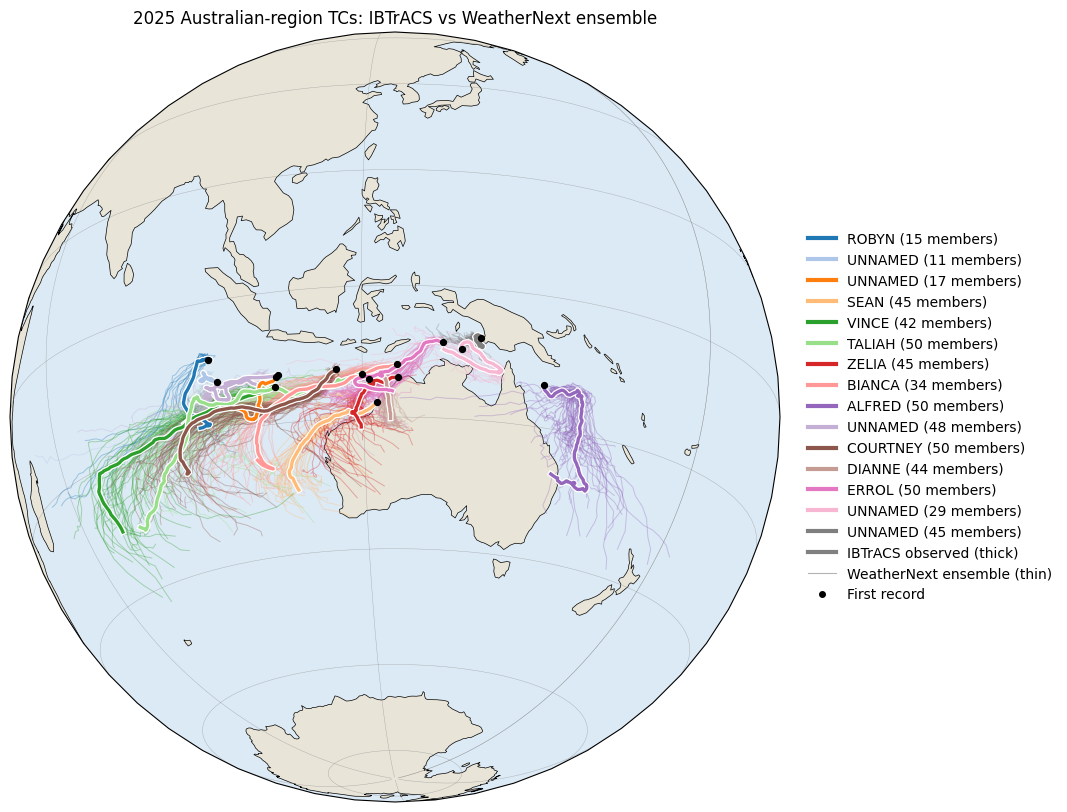

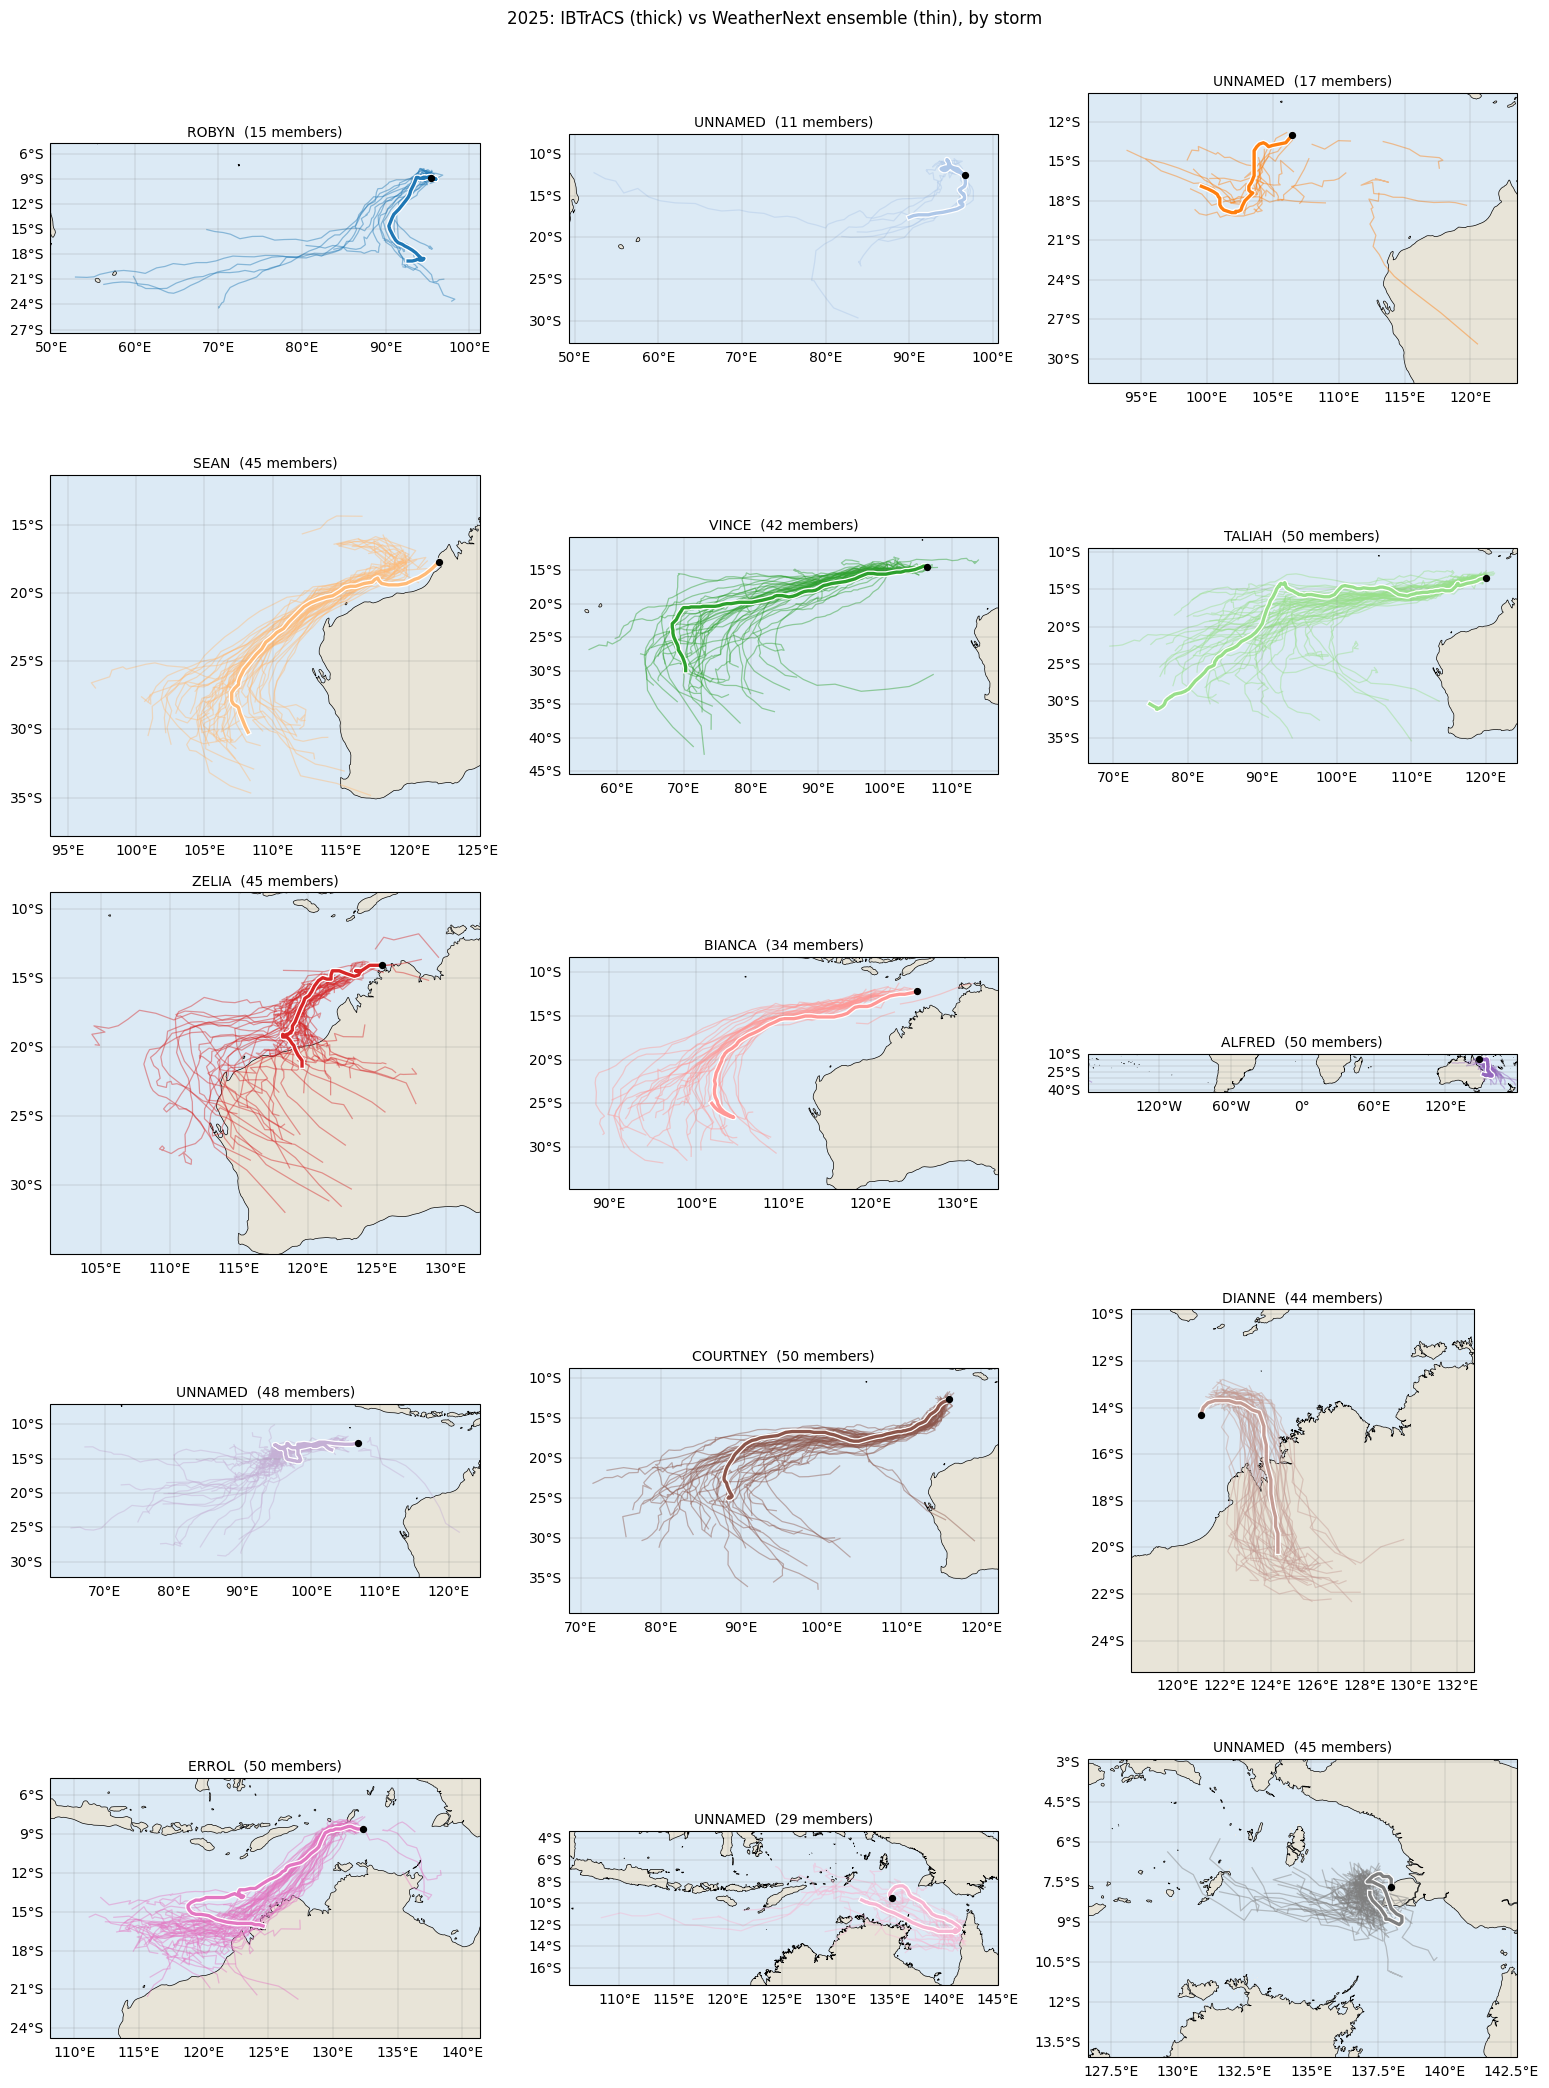

In [ ]:
# load the CSV once and reuse it across calls (it's big)
ibtracs = pd.read_csv(IBTRACS_PATH, low_memory=False)


# storms, ai_tracks, figs = plot_au_cyclones(2022, ibtracs=ibtracs, ai_dir="../TC_datasets/WN-C")
# storms, ai_tracks, figs = plot_au_cyclones(2023, ibtracs=ibtracs, ai_dir="../TC_datasets/WN-C")
# storms, ai_tracks, figs = plot_au_cyclones(2024, ibtracs=ibtracs, ai_dir="../TC_datasets/WN-C")
storms, ai_tracks, figs = plot_au_cyclones(2025, ibtracs=ibtracs, ai_dir="../TC_datasets/WN-C")

# plot_au_cyclones(range(1980, 2021), ibtracs=ibtracs, panels=True)
# plot_au_cyclones(range(2018, 2024), ibtracs=ibtracs, ai_dir="../TC_datasets/WN-C")


In [ ]:
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import box
import cartopy.io.shapereader as shpreader
import matplotlib.pyplot as plt
from pathlib import Path

KT = 0.514444  # m/s per knot


def australia_geom(buffer_km=0, max_lon=None, resolution="10m"):
    """Australia land polygon. buffer_km>0 turns 'landfall' into 'within X km' (approx, 111 km/deg)."""
    shp = shpreader.natural_earth(resolution, "cultural", "admin_0_countries")
    geoms = [r.geometry for r in shpreader.Reader(shp).records()
             if r.attributes.get("ADMIN") == "Australia"]
    geom = shapely.union_all(geoms)
    if max_lon is not None:                      # e.g. 155 to match your exposure cutoff
        geom = geom.intersection(box(-180, -90, max_lon, 90))
    if buffer_km:
        geom = geom.buffer(buffer_km / 111.0)
    shapely.prepare(geom)
    return geom


def _densify(lon, lat, t, n=6):
    lon = np.rad2deg(np.unwrap(np.deg2rad(np.asarray(lon, float))))
    lat = np.asarray(lat, float)
    ti = np.asarray(t).astype("datetime64[ns]").astype("int64")
    x = np.arange(len(lon))
    xi = np.linspace(0, len(lon) - 1, (len(lon) - 1) * n + 1)
    lo = (np.interp(xi, x, lon) + 180) % 360 - 180
    return lo, np.interp(xi, x, lat), np.interp(xi, x, ti).astype("int64").astype("datetime64[ns]")


def ensemble_stats(storms, ai_tracks, ibtracs, ai_dir, only_hit=True,
                   buffer_km=0, max_lon=None, densify_n=6):
    """
    storms, ai_tracks : as returned by plot_au_cyclones
    ibtracs           : the loaded IBTrACS DataFrame
    Returns (storm_df, season_df, member_df)
    """
    ai_dir = Path(ai_dir)
    geom = australia_geom(buffer_km, max_lon)

    obs = ibtracs[ibtracs["SID"].isin(storms["SID"])].copy()
    for c in ["LAT", "LON", "WMO_WIND", "BOM_WIND"]:
        if c in obs: obs[c] = pd.to_numeric(obs[c], errors="coerce")
    obs["ISO_TIME"] = pd.to_datetime(obs["ISO_TIME"], errors="coerce")
    obs = obs.dropna(subset=["LAT", "LON", "ISO_TIME"]).sort_values(["SID", "ISO_TIME"])
    obs_by_sid = {s: g for s, g in obs.groupby("SID")}

    storm_rows, member_rows = [], []
    for r in storms.itertuples():
        sid = r.SID
        g = obs_by_sid[sid]
        lo, la, ti = _densify(g["LON"], g["LAT"], g["ISO_TIME"].values, densify_n)
        on_land = shapely.contains_xy(geom, lo, la)
        if only_hit and not on_land.any():
            continue
        t_land = ti[on_land][0] if on_land.any() else None
        obs_wind = g["WMO_WIND"].fillna(g["BOM_WIND"]) if "BOM_WIND" in g else g["WMO_WIND"]

        f = ai_dir / f"{sid}.csv"
        n_samples = (pd.read_csv(f, comment="#", usecols=["sample"])["sample"].nunique()
                     if f.is_file() else np.nan)

        members = ai_tracks.get(sid, [])
        for ds in members:
            mlo, mla, mti = _densify(ds.lon.values, ds.lat.values, ds.time.values, densify_n)
            m_land = shapely.contains_xy(geom, mlo, mla)
            hit = bool(m_land.any())
            covers = bool(t_land is not None and mti[-1] >= t_land)
            terr = ((mti[m_land][0] - t_land) / np.timedelta64(1, "h")
                    if hit and t_land is not None else np.nan)
            member_rows.append(dict(
                SID=sid, member=ds.attrs["id_no"], hit=hit, covers_obs_landfall=covers,
                landfall_time_err_h=terr,
                peak_wind_kt=float(ds.max_sustained_wind.max()) / KT,
                min_pressure=float(ds.central_pressure.min()),
                length_h=(mti[-1] - mti[0]) / np.timedelta64(1, "h"),
            ))

        storm_rows.append(dict(
            SEASON=r.SEASON, SID=sid, NAME=r.NAME, obs_hit=bool(on_land.any()),
            obs_peak_kt=obs_wind.max(), n_samples=n_samples, n_matched=len(members),
        ))

    storm_df = pd.DataFrame(storm_rows)
    member_df = pd.DataFrame(member_rows)
    if storm_df.empty:
        return storm_df, pd.DataFrame(), member_df

    agg = (member_df.groupby("SID").agg(
        n_hit=("hit", "sum"),
        n_cover=("covers_obs_landfall", "sum"),
        ens_peak_kt_mean=("peak_wind_kt", "mean"),
        ens_peak_kt_max=("peak_wind_kt", "max"),
        mean_length_h=("length_h", "mean"),
        landfall_time_err_h_med=("landfall_time_err_h", "median"),
    ).reset_index())
    # members that both cover the observed landfall time AND hit
    cov_hit = (member_df[member_df.covers_obs_landfall].groupby("SID")["hit"].sum()
               .rename("n_hit_of_covering").reset_index())
    storm_df = storm_df.merge(agg, on="SID", how="left").merge(cov_hit, on="SID", how="left")
    storm_df[["n_hit", "n_cover", "n_hit_of_covering"]] = \
        storm_df[["n_hit", "n_cover", "n_hit_of_covering"]].fillna(0).astype(int)
    storm_df["match_frac"] = storm_df["n_matched"] / storm_df["n_samples"]
    storm_df["landfall_frac"] = storm_df["n_hit"] / storm_df["n_matched"].replace(0, np.nan)
    storm_df["landfall_frac_covering"] = storm_df["n_hit_of_covering"] / storm_df["n_cover"].replace(0, np.nan)
    storm_df["peak_bias_kt"] = storm_df["ens_peak_kt_mean"] - storm_df["obs_peak_kt"]

    season_df = storm_df.groupby("SEASON").agg(
        n_storms=("SID", "nunique"),
        n_samples=("n_samples", "sum"),
        n_matched=("n_matched", "sum"),
        n_hit=("n_hit", "sum"),
        n_cover=("n_cover", "sum"),
        n_hit_of_covering=("n_hit_of_covering", "sum"),
        mean_storm_landfall_frac=("landfall_frac", "mean"),
        mean_peak_bias_kt=("peak_bias_kt", "mean"),
    )
    season_df["match_frac"] = season_df["n_matched"] / season_df["n_samples"]
    season_df["landfall_frac_pooled"] = season_df["n_hit"] / season_df["n_matched"]
    season_df["landfall_frac_covering"] = season_df["n_hit_of_covering"] / season_df["n_cover"]
    return storm_df, season_df.reset_index(), member_df


def plot_stats(storm_df):
    d = storm_df.sort_values(["SEASON", "SID"]).reset_index(drop=True)
    labels = [f"{n if n != 'NOT_NAMED' else s[-6:]}\n{int(y)}"
              for n, s, y in zip(d.NAME, d.SID, d.SEASON)]
    fig, ax = plt.subplots(figsize=(max(6, 0.7 * len(d)), 4))
    x = np.arange(len(d))
    ax.bar(x - 0.2, d["match_frac"], 0.4, label="matched / samples", color="#9ecae1")
    ax.bar(x + 0.2, d["landfall_frac"], 0.4, label="landfall / matched", color="#d73027")
    ax.scatter(x + 0.2, d["landfall_frac_covering"], color="k", s=14, zorder=3,
               label="landfall / members covering obs landfall time")
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylim(0, 1.05); ax.legend(fontsize=8, frameon=False)
    ax.set_title("Ensemble statistics for storms that hit Australia")
    plt.tight_layout(); plt.show()


 SEASON  n_storms  n_samples  n_matched  n_hit  n_cover  n_hit_of_covering  mean_storm_landfall_frac  mean_peak_bias_kt  match_frac  landfall_frac_pooled  landfall_frac_covering
   2025         5        0.0        234    121      155                 92                      0.53             -10.97         inf                  0.52                    0.59
 SEASON           SID   NAME  obs_hit  obs_peak_kt  n_samples  n_matched  n_hit  n_cover  ens_peak_kt_mean  ens_peak_kt_max  mean_length_h  landfall_time_err_h_med  n_hit_of_covering  match_frac  landfall_frac  landfall_frac_covering  peak_bias_kt
   2025 2025017S18122   SEAN     True         95.0        NaN         45      1       45             71.77             99.8         138.67                     69.0                  1         NaN           0.02                    0.02        -23.23
   2025 2025039S14125  ZELIA     True        115.0        NaN         45     39       39             67.84            123.2         146.40          

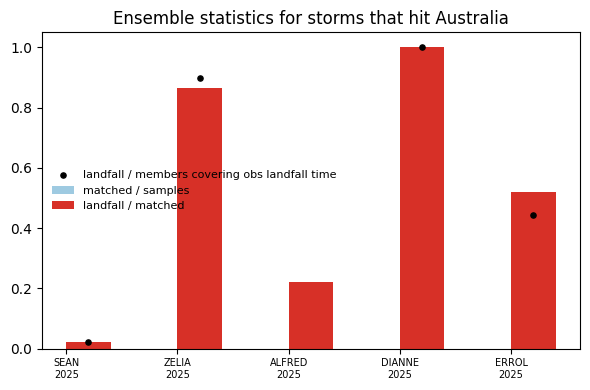

In [ ]:

storm_df, season_df, member_df = ensemble_stats(storms, ai_tracks, ibtracs,
                                                ai_dir="../TC_datasets/MiniTC-QM")

print(season_df.round(2).to_string(index=False))
print(storm_df.round(2).to_string(index=False))
plot_stats(storm_df)
